# Banning five path algorithms in one prompt — demo notebook

**Question.** Ask an LLM to "write a path-finding function" and it writes the same algorithm almost every time (here: BFS). If the prompt *forbids* the usual answers, does the model move to a *neighbouring* algorithm in its own activation space, jump to the *opposite side*, or simply ignore the ban?

**The experiment (artifact `art_IVZc3TWCeE9f`).** Qwen3-8B (thinking off, vLLM 0.11, temperature 1.0) solves a grid path-finding task (T1: `solve(grid, start, goal)`). It does so under a baseline prompt, a single ban of BFS, and four multi-name bans:
- **TOP**: BFS, DFS, greedy, IDDFS;
- **ARC**: BFS, BiBFS, A*, greedy;
- **SCATTER**: BFS, DFS, greedy, IDA*;
- **TOP5**: the literal five-name ban, TOP + A*.

Every program is labelled by its **mechanism** (runtime tracer + AST rules + a blind LLM judge on disagreement) and placed in **activation space**: the layer-24 residual stream, teacher-forced under a name-free baseline prompt. Before any multi-ban was sampled, six landing forecasts per set were computed from **FRLP** cells (forced-ratio latent probabilities: teacher-forced likelihoods of the model's own forced programs). They were sha256 **hash-chained** together with the analysis script.

**Full-run results (N = 100 programs per condition, 5 templates × 20).**

| Condition | Banned | Programs written | Avoidance |
|---|---|---|---|
| Baseline | – | BFS 100 | – |
| Single ban | BFS | DFS 86, BFS 14 | 0.86 |
| TOP | BFS, DFS, greedy, IDDFS | BFS 59, DFS 26, greedy 2, other 13 | 0.13 |
| ARC | BFS, BiBFS, A*, greedy | BFS 63, DFS 37 (a survivor) | 0.37 |
| SCATTER | BFS, DFS, greedy, IDA* | BFS 69, DFS 27, A* 2, other 2 | 0.04 |
| TOP5 | BFS, DFS, greedy, IDDFS, A* | BFS 63, DFS 36, IDDFS 1 | 0.00 |

- **A single ban works; a list ban does not.** With one ban, the model substitutes the next default (DFS). With four or five names banned, it keeps writing the banned BFS or DFS, and 41–92% of those programs never name their mechanism (DFS becomes "backtracking").
- **The list content barely matters (post hoc).** The BFS/DFS mix is the same across the four lists (chi-square p = 0.48), whether or not DFS is on the list. A long list acts like a generic perturbation of the default, not a list-specific veto.
- **The FRLP forecasts foresaw the failure** for TOP, SCATTER and TOP5 (implied avoidance < 1e-8). They did not foresee it for ARC (0.9995 implied vs 0.37 realised).

**What this notebook runs.** `method.py` is an orchestrator with one sub-command per stage. Sampling (vLLM) and teacher-forced scoring (Hugging Face) need a GPU (about one RTX-4090 hour), so their outputs come with the demo data. Every CPU stage is re-run with the original code on a curated subset of 100 programs (`mini_demo_data.json`):

| Stage | Original module | In this notebook |
|---|---|---|
| S1 freeze | `mb/prompts.py` | rebuild the sampled ban prompts, compare with the stored and committed ones |
| S2 sampling | `mb/gen.py` (vLLM, GPU) | not run: the sampled programs are the demo data |
| S3 label | `labeller_ext/ast_rules.py`, `combine.py` | re-run the AST labeller and the combine rule on all 100 programs |
| S4 keep | `mb/stages.py` | re-apply the keep rule to the stored forced-program counts |
| S5 / S7 scoring | `mb/score*.py` (HF, GPU) | not run: the FRLP cells come with the demo data |
| S6 select | `mb/sets.py` | geodesic geometry, Held-Karp seriation, TOP / ARC / SCATTER from the demo activations |
| S7 commit | `mb/forecasts.py` | recompute the six forecasts from the FRLP cells; verify the sha256 hash chain |
| S10 landing | `analysis/landing.py` | landing, avoidance, disguise and landing tests on the demo programs |
| S11 manifold | `analysis/manifold.py` | activation-space manifold (MDS, Isomap), landing arrows, persistent homology |
| S12 outputs | `mb/outputs.py` | re-derive the per-row `predict_*` forecasts |

The original functions are copied unchanged. The only edits are marked `# notebook:`: file locations, the repetition counts of the config cell, figures shown inline instead of closed, and the parts that need data outside the demo subset.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru (logging of every stage) and ripser (persistent homology in S11) — NOT on Colab, always install
_pip('loguru==0.7.3')
_pip('ripser==0.6.12')

# numpy, pandas, scipy, scikit-learn, matplotlib — pre-installed on Colab, install locally only (Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# --- method.py: the original import block ---
import argparse
import sys
import time

from loguru import logger

# from common import DATA_DIR, setup_logging   # notebook: common.py is the "frozen protocol" cell below

# --- imports of the modules method.py dispatches to (common.py, mb/, labeller_ext/, analysis/) ---
import ast
import base64
import collections
import copy
import hashlib
import itertools
import json
import math
import os
import re
import tempfile
from datetime import datetime, timezone
from pathlib import Path
from types import SimpleNamespace
from typing import Any, Iterable

import numpy as np

# --- notebook additions: tables, inline figures, the post hoc test of the summary ---
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from scipy.linalg import orthogonal_procrustes
from scipy.sparse import SparseEfficiencyWarning
from scipy.stats import chi2_contingency

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

import warnings
# notebook: with 42 forced programs the PCA keeps about as many dimensions as there are points, so ripser and Isomap
# warn on every call (a point cloud wider than tall; a 10-NN graph in 2 components that Isomap completes). Expected.
warnings.filterwarnings("ignore", message="The input point cloud has more columns than rows")
warnings.filterwarnings("ignore", message="The input matrix is square, but the distance_matrix flag is off")
warnings.filterwarnings("ignore", message="The number of connected components of the neighbors graph")
warnings.filterwarnings("ignore", category=SparseEfficiencyWarning)

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-2/experiment-9/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["metadata"]["description"])
print(f'{len(data["datasets"][0]["examples"])} programs of {data["datasets"][0]["dataset"]}:',
      data["metadata"]["selection"]["counts"])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Curated demo subset of the T1 grid-path dataset of 'Banning five path algorithms in one prompt' (Qwen3-8B, thinking off): 100 programs with labels, response text and layer-24 residual states, plus the committed protocol artifacts the CPU-only stages read.
100 programs of T1_grid_path: {'forced:bfs': 6, 'forced:dfs': 6, 'forced:bibfs': 6, 'forced:iddfs': 6, 'forced:astar': 6, 'forced:gbfs': 6, 'forced_desc:idastar': 6, 'baseline': 8, 'single:bfs': 10, 'multi:TOP': 10, 'multi:ARC': 10, 'multi:SCATTER': 10, 'multi:TOP5': 10}


## Configuration

The demo data fixes the *size* of the analysis: 100 programs, one layer (24) and two token positions (g16, `pre`) of the residual stream, where the original used layers 20–28 and four positions. The knobs below set how many bootstrap, null and restart repetitions each analysis draws. They are set to the original values of the full run (`# original:` comments). At this size the whole notebook takes about a minute on a CPU, most of it package installation. Lower the counts for a faster pass.

In [5]:
# ---- repetition counts (the original values of the full run; original values in the comments) ----
N_BOOT = 2000                  # S10 template-cluster bootstrap replicates            (original: 2000)
DRY_RUN_REPS = 200             # S10 dry run: uniform-null replicates                 (original: 200)
SET_BOOT = 200                 # S6 program-bootstrap resamples of the set selection  (original: 200)
GEO_BOOT = 200                 # S11 program bootstrap of the nearest neighbours      (original: 200)
K_SWEEP = (5, 10, 15, 20)      # k of the k-NN geodesic graph                         (original: (5, 10, 15, 20))
MDS_N_INIT = 8                 # SMACOF restarts of the metric MDS                    (original: 8)
PERSIST_BOOT_PER_ALG = 40      # bootstrap centroids per algorithm (persistent H1)    (original: 40)
PERSIST_N_SHUFFLE = 200        # label-shuffled null replicates                       (original: 200)
PERSIST_N_GAUSS = 100          # covariance-matched Gaussian null replicates          (original: 100)
PERSIST_N_SUB = 50             # 80% subsamples for the persistence check             (original: 50)

# ---- what the demo data holds (fixed by mini_demo_data.json) ----
LAYERS = [24]                  # residual-stream layers                               (original: list(range(20, 29)))
POSITIONS = ("g16", "pre")     # state positions                                      (original: g8, g16, g32, pre)

## The frozen protocol (`common.py`)

Everything that defines the protocol lives in one module, so every stage reads one frozen definition:
- the task text and the 10-algorithm grid catalogue with display names and one-line definitions;
- the W1–W5 ban, mention and neutral templates;
- the thresholds: keep rule 70%, gate = avoidance ≥ 0.5 with ≥ 20 non-banned programs;
- the Wilson interval and the sha256 hash-chain helpers.

Copied unchanged, except that `ROOT` points to a scratch copy of the artifact's folder layout and `LAYERS` comes from the config cell.

In [6]:
# notebook: ROOT is a scratch copy of the artifact's folder layout (original: Path(__file__).resolve().parent)
ROOT = Path(tempfile.mkdtemp(prefix="multiban_demo_"))
CANON = ROOT / "canon"
TASK_DIR = ROOT / "tasks"
PROMPT_DIR = ROOT / "prompts"
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
LABEL_DIR = ROOT / "labeller_ext"
STATES_DIR = ROOT / "states"
COMMIT_LOG = ROOT / "commitments.log"

for _d in (PROMPT_DIR, DATA_DIR, RESULTS_DIR, FIG_DIR, LOG_DIR, STATES_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# Declared dependency art_j3Rm_lr2nzR6 (gen_art_dataset_1, the algorithm-choice source data): read through ONE constant,
# overridable with MB_DEP_DATASET; by default the published sibling folder next to this artifact.
DS_FILE = Path(os.environ.get("MB_DEP_DATASET", str(ROOT.parent / "gen_art_dataset_1" / "full_data_out.json")))

MODEL_ID = os.environ.get("MB_MODEL", "Qwen/Qwen3-8B")
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"
SERVED_NAME = "qwen3-multiban"
VLLM_PORT = int(os.environ.get("MB_VLLM_PORT", "8019"))
VLLM_URL = f"http://127.0.0.1:{VLLM_PORT}"
JUDGE_MODEL = "openai/gpt-4.1-mini"
GOLD_JUDGES = ("openai/gpt-4.1-mini", "google/gemini-2.5-flash")
GOLD_TIEBREAK = "deepseek/deepseek-chat-v3.1"
JUDGE_CAP_USD = 0.70

TASKS = ("t1", "t2")
TASK_DATASET_NAME = {"t1": "T1_grid_path", "t2": "T2_weighted_shortest_path"}
TASK_SUBDIR = {"t1": "t1_grid", "t2": "t2_wsp"}

# Task text: verbatim copy of iteration-1 exp1 (asserted equal to canon/prompts/conditions.json['spec'] at freeze time).
T1_DESCRIPTION = (
    "Task: write a Python function solve(grid, start, goal) that finds a path between two cells of a grid. "
    "grid is a list of equal-length strings with between 1 and 30 rows and between 1 and 30 columns; "
    "the character . is a free cell and the character # is a wall. start and goal are (row, col) tuples of "
    "0-based indices. A move goes to one of the 4 orthogonal neighbours (up, down, left, right) and may not "
    "leave the grid or enter a wall. Return a list of (row, col) tuples that begins with start, ends with goal, "
    "and in which consecutive cells are neighbours and every cell is free. Any valid path is accepted; it does "
    "not have to be the shortest. If start equals goal and the cell is free, return [start]. If no path exists, "
    "or start or goal is a wall, return []."
)
T2_DESCRIPTION = (
    "Task: write a Python function solve(n, edges, s, t) that returns the length of the shortest path from node "
    "s to node t in a directed weighted graph. Nodes are numbered 0 to n-1 with 1 <= n <= 100. edges is a list "
    "of (u, v, w) tuples, each a directed edge from u to v with integer weight 0 <= w <= 100; there are at most "
    "600 edges and the graph may contain cycles, self-loops and parallel edges. Return the minimum total weight "
    "of a path from s to t as an int, 0 if s equals t, and -1 if t cannot be reached from s."
)
FORMAT_TEXT = (
    "Use only the Python standard library. Return only one ```python code block containing the function solve "
    "and any helpers, with no example usage and no explanation."
)
DESCRIPTION = {"t1": T1_DESCRIPTION, "t2": T2_DESCRIPTION}


def spec_text(task: str) -> str:
    """SPEC = DESCRIPTION + blank line + FORMAT."""
    return DESCRIPTION[task] + "\n\n" + FORMAT_TEXT


# Catalogues (key -> frozen display name), in CANONICAL LIST ORDER.
CATALOGUE: dict[str, dict[str, str]] = {
    "t1": {
        "bfs": "breadth-first search (BFS)",
        "dfs": "depth-first search (DFS)",
        "bibfs": "bidirectional BFS",
        "iddfs": "iterative deepening DFS (IDDFS)",
        "astar": "A* search",
        "gbfs": "greedy best-first search",
        "dijkstra_unit": "unit-weight Dijkstra",
        "idastar": "IDA* search",
        "jps": "jump point search",
        "biastar": "bidirectional A* search",
    },
    "t2": {
        "dijkstra": "Dijkstra's algorithm",
        "bf_spfa": "Bellman-Ford or SPFA",
        "bidijkstra": "bidirectional Dijkstra",
        "floyd": "Floyd-Warshall",
        "dial": "Dial's bucket-queue algorithm",
    },
}
MODES = {t: list(CATALOGUE[t].keys()) for t in TASKS}
NEW_T1 = ("gbfs", "idastar", "jps", "biastar")
OTHER = "other"
UNKNOWN = "unknown"
NO_CODE = "no_code"
SHORT = {"bfs": "BFS", "dfs": "DFS", "bibfs": "BiBFS", "iddfs": "IDDFS", "astar": "A*", "gbfs": "GBFS",
         "dijkstra_unit": "Dijkstra(u)", "idastar": "IDA*", "jps": "JPS", "biastar": "BiA*",
         "dijkstra": "Dijkstra", "bf_spfa": "BF/SPFA", "bidijkstra": "BiDijkstra", "floyd": "Floyd",
         "dial": "Dial", "other": "other", "unknown": "unknown", "no_code": "no code"}

# One-line definitions shown to the strategy-blind judge (never the condition).
MODE_DEFINITIONS: dict[str, dict[str, str]] = {
    "t1": {
        "bfs": "breadth-first search: explores cells in order of distance from start with a FIFO queue (deque.popleft, "
               "list.pop(0), queue.Queue) or level-by-level frontier lists; one search direction; no priority queue.",
        "dfs": "depth-first search: follows one branch as deep as possible with recursion or a LIFO stack, with a "
               "visited set; a single pass with no depth limit and no restarts (neighbour ordering by distance is "
               "still DFS).",
        "bibfs": "bidirectional BFS: two breadth-first searches, one from start and one from goal, expanded alternately "
                 "until the frontiers meet; the path is joined at the meeting cell; no heuristic, no heap.",
        "iddfs": "iterative deepening DFS: repeated depth-limited depth-first searches with an increasing depth limit "
                 "(0, 1, 2, ...) until the goal is found; no heuristic bound.",
        "astar": "A* search: a priority queue (heap) ordered by f = g + h, cost so far plus a heuristic such as the "
                 "Manhattan distance to the goal; one search direction.",
        "gbfs": "greedy best-first search: a priority queue ordered by the heuristic h alone (e.g. Manhattan distance "
                "to the goal), ignoring the cost so far; one search direction.",
        "dijkstra_unit": "Dijkstra's algorithm on the unit-weight grid: a priority queue (heap) ordered by distance from "
                         "start only, with no heuristic toward the goal.",
        "idastar": "IDA*: repeated depth-first searches bounded by f = g + h (heuristic, e.g. Manhattan), raising the "
                   "bound to the smallest f that exceeded it, until the goal is found.",
        "jps": "jump point search: A*-style search that 'jumps' along straight lines (and, for 8-connected variants, "
               "diagonals) and adds cells to the open list only at jump points (turning points next to walls, or the "
               "goal), instead of adding every neighbour.",
        "biastar": "bidirectional A*: two A* searches, forward from start toward goal and backward from goal toward "
                   "start, each with its own heuristic-ordered heap, stopping when the frontiers meet.",
    },
    "t2": {
        "dijkstra": "Dijkstra's algorithm: a single priority queue (heap) of tentative distances from s, popping the "
                    "smallest distance each time (lazy deletion or decrease-key variants), one search direction.",
        "bf_spfa": "Bellman-Ford (repeated relaxation passes over all edges, up to n-1 rounds, possibly with early exit) "
                   "or SPFA (a FIFO queue of nodes whose distance improved, often with an in-queue flag).",
        "bidijkstra": "bidirectional Dijkstra: two Dijkstra searches, forward from s on the graph and backward from t on "
                      "the reversed graph, with a meeting/stopping rule.",
        "floyd": "Floyd-Warshall: all-pairs shortest paths with a triple loop over k, i, j updating "
                 "dist[i][j] = min(dist[i][j], dist[i][k] + dist[k][j]).",
        "dial": "Dial's algorithm: Dijkstra with a bucket queue, i.e. an array or dict of buckets indexed by distance, "
                "scanned in increasing distance order instead of a binary heap.",
    },
}
EXTENDED_CATALOGUE = {
    "t1": ["bidirectional Dijkstra on the grid", "beam search", "random walk", "wall following"],
    "t2": ["DAG dynamic programming", "Johnson's algorithm", "A* with a non-zero heuristic"],
}

# Shared protocol v2: frozen W1-W5 (ban, mention, neutral) templates.
W_TEMPLATES: list[dict[str, str]] = [
    {"ban": "Do not use {X} for this task.", "mention": "You could use {X} for this task.",
     "neutral": "Do not use {N} for this task."},
    {"ban": "Your solution must not rely on {X}.", "mention": "Your solution may rely on {X}.",
     "neutral": "Your solution must not rely on {N}."},
    {"ban": "Avoid {X} entirely.", "mention": "Consider {X} first.", "neutral": "Avoid {N} entirely."},
    {"ban": "{X} is not allowed here.", "mention": "{X} is allowed here.", "neutral": "{N} is not allowed here."},
    {"ban": "Write a correct solution that does not use {X}.", "mention": "Write a correct solution that may use {X}.",
     "neutral": "Write a correct solution that does not use {N}."},
]
NONCE_NAME = "the Zorblax method"
PAD_FILLER = " Thanks."

# Forced paraphrases: the 5 exp1 forced templates are read from canon/prompts/conditions.json; these 5 are new.
# 'Solve this task with {j}.' duplicates exp1's third forced template verbatim, so it is replaced by
# 'Apply {j} to solve this task.' (logged deviation D-forced-dup).
FORCED_NEW = ["Apply {X} to solve this task.", "Your solution should implement {X}.", "Please write {X} for this task.",
              "Base your solution on {X}.", "Use {X} as the algorithm here."]
FORCED_NEW_PLANNED_DUPLICATE = "Solve this task with {X}."
DESCRIPTIVE: dict[str, str] = {
    "bidijkstra": "run Dijkstra forward from s and backward from t over reversed edges at the same time and stop when "
                  "the two searches meet",
    "biastar": "run A* forward from start and backward from goal at the same time, each guided by the Manhattan "
               "distance to its own target, and stop when the frontiers meet",
    "jps": "on this 4-connected grid, jump in straight lines and add a cell to the open list only at turning points "
           "next to walls or at the goal",
    "idastar": "repeat a depth-first search bounded by f = g + Manhattan distance, raising the bound to the smallest f "
               "that exceeded it",
    "gbfs": "always expand the frontier cell with the smallest Manhattan distance to the goal, ignoring the cost so far",
    "iddfs": "repeat a depth-limited DFS with limits 0, 1, 2, ... until the goal is found",
    "dial": "Dijkstra with an array of buckets indexed by tentative distance instead of a heap",
}

# Alias lexicon (case-insensitive substrings) for disguise and scrub steps; keyed by mechanism family.
ALIASES: dict[str, list[str]] = {
    "bfs": ["bfs", "breadth-first", "breadth first", "breadth_first"],
    "dfs": ["dfs", "depth-first", "depth first", "depth_first"],
    "astar": ["a*", "a-star", "astar", "a_star"],
    "gbfs": ["greedy", "best-first", "best first", "best_first"],
    "iddfs": ["iddfs", "iterative deepening", "iterative_deepening"],
    "idastar": ["ida*", "ida_star", "idastar"],
    "jps": ["jps", "jump point", "jump_point"],
    "bidir": ["bidirectional", "bidir"],
    "dijkstra": ["dijkstra"],
    "bf_spfa": ["bellman", "ford", "spfa"],
    "floyd": ["floyd", "warshall"],
    "dial": ["dial", "bucket queue", "bucket_queue"],
}
# Which alias families name each mechanism (a program 'names its own mechanism' if any family matches).
MECH_ALIAS_FAMILIES: dict[str, list[str]] = {
    "bfs": ["bfs"], "dfs": ["dfs"], "bibfs": ["bidir"], "iddfs": ["iddfs"], "astar": ["astar"], "gbfs": ["gbfs"],
    "dijkstra_unit": ["dijkstra"], "idastar": ["idastar"], "jps": ["jps"], "biastar": ["bidir"],
    "dijkstra": ["dijkstra"], "bf_spfa": ["bf_spfa"], "bidijkstra": ["bidir"], "floyd": ["floyd"], "dial": ["dial"],
}

THRESHOLDS = {"keep_forced_share": 0.70, "smoke_descriptive_min": 7, "gate_avoidance": 0.50, "gate_min_nonbanned": 20,
              "uniform_mix": 0.05, "other_floor": 0.02, "ess_flag": 5.0, "gold_accept": 36, "gold_per_algo_min": 3}
DECODING = {"temperature": 1.0, "top_p": 1.0, "top_k": -1, "max_tokens": 1024, "thinking": "off"}
DECODING_TAG = "T1.0_topp1.0_topk-off_max1024_thinkoff"
# LAYERS = list(range(20, 29))  # notebook: the demo data holds layer 24 only -> LAYERS is set in the config cell
GEN_POSITIONS = ("g8", "g16", "g32", "pre")
N_PER_TEMPLATE = 20
M_MAX = 30


def setup_logging(name: str) -> None:
    """loguru: stdout INFO + rotating DEBUG file sink per stage."""
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()


def request_seed(*parts: Any) -> int:
    """Per-request seed = int(sha256('task|condition|template|paraphrase')[:8], 16)."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest()[:8], 16)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    rows: list[dict[str, Any]] = []
    p = Path(p)
    if not p.exists():
        return rows
    with p.open() as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    rows.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping malformed jsonl line in {p.name}")
    return rows


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with tmp.open("w") as fh:
        for r in rows:
            fh.write(json.dumps(r, ensure_ascii=False, default=_json_default) + "\n")
    tmp.replace(p)


def write_json(p: Path, obj: Any, indent: int | None = 1, sort_keys: bool = False) -> None:
    p = Path(p)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=indent, sort_keys=sort_keys, ensure_ascii=False, default=_json_default))
    tmp.replace(p)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def _json_default(o: Any) -> Any:
    try:
        import numpy as np  # local import: keeps the sandbox runner free of numpy

        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return None if not np.isfinite(o) else float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
        if isinstance(o, np.bool_):
            return bool(o)
    except ImportError:
        pass
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if isinstance(o, Path):
        return str(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def canonical_json(obj: Any) -> str:
    return json.dumps(obj, sort_keys=True, separators=(",", ":"), ensure_ascii=False, default=_json_default)


def wilson_ci(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n <= 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, centre - half), min(1.0, centre + half))


def join_names_or(names: list[str]) -> str:
    """'A', 'A or B', 'A, B or C' (order preserved)."""
    if len(names) == 1:
        return names[0]
    return ", ".join(names[:-1]) + " or " + names[-1]


def cap_first(s: str) -> str:
    return s[:1].upper() + s[1:] if s else s


def rotate(xs: list[Any], k: int) -> list[Any]:
    if not xs:
        return xs
    k %= len(xs)
    return xs[k:] + xs[:k]


def logsumexp(xs: list[float]) -> float:
    if not xs:
        return float("-inf")
    m = max(xs)
    if m == float("-inf"):
        return m
    return m + math.log(sum(math.exp(x - m) for x in xs))


def logmeanexp(xs: list[float]) -> float:
    return logsumexp(xs) - math.log(len(xs)) if xs else float("nan")


# ------------------------------------------------------------------------------------------------ commitments
def read_commitments() -> list[dict[str, Any]]:
    return read_jsonl(COMMIT_LOG)


def commit_payload(payload_path: Path, note: str = "") -> dict[str, Any]:
    """Append a hash-chained line {i, utc_time, prev_line_sha256, payload_sha256, payload_path, note} to commitments.log.
    payload_sha256 = sha256 of the canonical sorted-key JSON of the payload (JSON files) or of the raw bytes
    (other files); prev_line_sha256 = sha256 of the previous line's exact text ('0'*64 for line 0)."""
    payload_path = Path(payload_path)
    lines = COMMIT_LOG.read_text().splitlines() if COMMIT_LOG.exists() else []
    prev = sha256_text(lines[-1]) if lines else "0" * 64
    if payload_path.suffix == ".json":
        psha = sha256_text(canonical_json(json.loads(payload_path.read_text())))
    else:
        psha = sha256_file(payload_path)
    entry = {"i": len(lines), "utc_time": utc_now(), "prev_line_sha256": prev, "payload_sha256": psha,
             "payload_path": str(payload_path.relative_to(ROOT)), "note": note}
    with COMMIT_LOG.open("a") as fh:
        fh.write(json.dumps(entry, sort_keys=True) + "\n")
    logger.info(f"committed {entry['payload_path']} sha={psha[:12]} (line {entry['i']})")
    return entry


def verify_chain() -> tuple[bool, list[str]]:
    """Recompute the chain and every payload hash; returns (ok, problems)."""
    problems: list[str] = []
    if not COMMIT_LOG.exists():
        return False, ["no commitments.log"]
    lines = COMMIT_LOG.read_text().splitlines()
    prev = "0" * 64
    for i, ln in enumerate(lines):
        e = json.loads(ln)
        if e["prev_line_sha256"] != prev:
            problems.append(f"line {i}: prev-line hash mismatch")
        p = ROOT / e["payload_path"]
        if not p.exists():
            problems.append(f"line {i}: payload missing {e['payload_path']}")
        else:
            psha = sha256_text(canonical_json(json.loads(p.read_text()))) if p.suffix == ".json" else sha256_file(p)
            if psha != e["payload_sha256"]:
                problems.append(f"line {i}: payload hash mismatch for {e['payload_path']}")
        prev = sha256_text(ln)
    return (not problems, problems)


def deviation(code: str, text: str) -> None:
    """Append one entry to results/deviations.json (deduplicated by code)."""
    p = RESULTS_DIR / "deviations.json"
    devs = json.loads(p.read_text()) if p.exists() else []
    if any(d["code"] == code for d in devs):
        return
    devs.append({"code": code, "text": text, "utc": utc_now()})
    write_json(p, devs)
    logger.warning(f"DEVIATION {code}: {text}")


def timing(key: str, seconds: float, units: int, note: str = "") -> None:
    """Record time-per-unit to logs/timing.json (staged scaling 10 -> 100 -> full)."""
    p = LOG_DIR / "timing.json"
    t = json.loads(p.read_text()) if p.exists() else {}
    t.setdefault(key, []).append({"seconds": round(seconds, 3), "units": units,
                                   "sec_per_unit": round(seconds / max(units, 1), 4), "note": note, "utc": utc_now()})
    write_json(p, t)

## The demo data in the artifact's file layout

The stage functions read their inputs from fixed files: `data/labelled_session*.jsonl`, `results/*.json`, `predictions/forecasts_*.json`, `states/t1/base/part_*.npz` and `commitments.log`. Instead of rewriting every reader, this cell writes the demo data into that layout under the scratch `ROOT`, so the original functions run unchanged:
- **labelled programs**:
  - `data/labelled_session1.jsonl`: baseline and the single ban;
  - `data/labelled_session2.jsonl`: the four multi-bans;
  - `data/program_sets.json`: the 42 forced programs, 6 per algorithm.
- **activation states** → `states/t1/base/part_001.npz`, in the array layout of `mb/score.py`:
  - all 100 programs at layer 24, at the 16th generated token (g16) and at `pre` (the token before the first mechanism evidence);
  - positions that are not in the demo data stay NaN.
- **committed artifacts**: the T1 FRLP cells, planned conditions, forecasts, the hash-chained `commitments.log` and the committed `analysis/landing.py`.

`load_states` (from `mb/score.py`) is copied unchanged.

In [7]:
MD = data["metadata"]
EXAMPLES = data["datasets"][0]["examples"]
POS_NAMES = GEN_POSITIONS  # mb/score.py: the state positions of X[:, layer, position, :]


def _row(ex: dict[str, Any]) -> dict[str, Any]:
    """A method_out.json example -> the labelled-row fields the stage functions read (data/labelled_*.jsonl)."""
    return {"task": ex["metadata_task"], "condition": ex["metadata_condition"], "template": ex["metadata_template"],
            "paraphrase_id": ex["metadata_paraphrase_id"], "sample_index": ex["metadata_sample_id"],
            "stage": ex["metadata_stage"], "label": ex["output"], "labeller_source": ex["metadata_labeller_source"],
            "code": ex.get("metadata_code"), "code_sha256": ex.get("metadata_code_sha256"),
            "text": ex.get("metadata_text"), "passed": ex.get("metadata_passed"),
            "truncated": ex.get("metadata_truncated"), "banned": ex.get("metadata_banned"),
            "algorithm": ex.get("metadata_requested_algorithm"), "uid": ex["metadata_uid"],
            "half": ex.get("metadata_half")}


def is_forced(r: dict[str, Any]) -> bool:
    return r["condition"].startswith(("forced:", "forced_desc:"))


def nm(keys) -> str:  # display helper: short algorithm names
    return ", ".join(SHORT.get(k, k) for k in keys) if keys else "-"


ROWS = [_row(e) for e in EXAMPLES]

# results/, predictions/, commitments.log and the committed analysis script
write_json(RESULTS_DIR / "catalogue_keep.json", MD["catalogue_keep"])
write_json(RESULTS_DIR / "sets_and_geometry.json", MD["sets_and_geometry"])  # committed full-run geometry
write_json(RESULTS_DIR / "planned_conditions.json", MD["planned_conditions"])
write_json(RESULTS_DIR / "aux_datasets.json", MD["aux_datasets"])
write_jsonl(RESULTS_DIR / "frlp_cells.jsonl", MD["frlp_cells_t1"])
(ROOT / "predictions").mkdir(exist_ok=True)
for set_name, fc in MD["forecasts"].items():
    write_json(ROOT / "predictions" / f"forecasts_{set_name}.json", fc)
COMMIT_LOG.write_text("\n".join(MD["commitments_log"]) + "\n")
(ROOT / "analysis").mkdir(exist_ok=True)
(ROOT / "analysis" / "landing.py").write_bytes(MD["analysis_landing_py"].encode("utf-8"))

# data/: labelled programs (session 1: baseline and the single ban; session 2: the multi-bans) and program sets
write_jsonl(DATA_DIR / "labelled_session1.jsonl", [r for r in ROWS if not is_forced(r) and r["stage"] == "s1"])
write_jsonl(DATA_DIR / "labelled_session2.jsonl", [r for r in ROWS if not is_forced(r) and r["stage"] == "s2"])
write_json(DATA_DIR / "program_sets.json",
           {f"t1:{a}": {"programs": [r for r in ROWS if is_forced(r) and r["algorithm"] == a]}
            for a in MD["selection"]["forced_algorithms"]})

# states/t1/base: X[program, layer, position, 4096] (float16) plus one meta record per program
enc = MD["state_encoding"]
X = np.full((len(EXAMPLES), len(LAYERS), len(POS_NAMES), 4096), np.nan, dtype=np.float16)
meta = []
for i, (e, r) in enumerate(zip(EXAMPLES, ROWS)):
    s = np.frombuffer(base64.b64decode(e["metadata_state_b64"]), dtype=enc["dtype"]).reshape(enc["shape"])
    for j, pos in enumerate(enc["positions"]):
        X[i, LAYERS.index(enc["layer"]), POS_NAMES.index(pos)] = s[j]
    m = {"uid": r["uid"], "task": r["task"], "label": r["label"], "context": "base",
         "pre_fallback": e["metadata_state_pre_fallback"], "n_tokens": e["metadata_state_n_tokens"]}
    if is_forced(r):
        m.update({"kind": "forced", "algorithm": r["algorithm"], "half": r["half"]})
    else:
        m.update({"kind": "natural", "condition": r["condition"], "template": r["template"],
                  "source": "session1" if r["stage"] == "s1" else "session2"})
    meta.append(m)
(STATES_DIR / "t1" / "base").mkdir(parents=True, exist_ok=True)
np.savez(STATES_DIR / "t1" / "base" / "part_001.npz", uids=np.array([r["uid"] for r in ROWS]), X=X,
         meta=np.array(json.dumps(meta)), R_keys=np.array([], dtype="<U1"),
         R=np.zeros((0, len(LAYERS), 4096), dtype=np.float16), layers=np.array(LAYERS), positions=np.array(POS_NAMES))


# mb/score.py
def load_states(task: str, context: str) -> dict[str, Any]:
    d = STATES_DIR / task / context
    uids, Xs, metas, R = [], [], [], {}
    for p in sorted(d.glob("part_*.npz")):
        z = np.load(p, allow_pickle=False)
        uids += list(z["uids"])
        Xs.append(z["X"])
        metas += json.loads(str(z["meta"]))
        for k, r in zip(z["R_keys"], z["R"]):
            R[str(k)] = r
    X = np.concatenate(Xs) if Xs else np.zeros((0, len(LAYERS), len(POS_NAMES), 4096), dtype=np.float16)
    return {"uids": uids, "X": X, "meta": metas, "R": R}


st_check = load_states("t1", "base")
print("artifact layout written to a temporary ROOT:",
      sorted(str(p.relative_to(ROOT)) for p in ROOT.rglob("*") if p.is_file() and "logs" not in p.parts))
print(f"states/t1/base: X {st_check['X'].shape} {st_check['X'].dtype};",
      dict(collections.Counter(m["kind"] for m in st_check["meta"])))

artifact layout written to a temporary ROOT: ['analysis/landing.py', 'commitments.log', 'data/labelled_session1.jsonl', 'data/labelled_session2.jsonl', 'data/program_sets.json', 'predictions/forecasts_ARC.json', 'predictions/forecasts_SCATTER.json', 'predictions/forecasts_TOP.json', 'predictions/forecasts_TOP5.json', 'results/aux_datasets.json', 'results/catalogue_keep.json', 'results/frlp_cells.jsonl', 'results/planned_conditions.json', 'results/sets_and_geometry.json', 'states/t1/base/part_001.npz']
states/t1/base: X (100, 1, 4, 4096) float16; {'forced': 42, 'natural': 58}


## The orchestrator (`method.py`)

`method.py` runs one stage per call (`uv run method.py <stage>`). The full run went:
1. freeze → recheck;
2. vLLM session 1: serve / smoke / s1main / forced_rest;
3. refs / validate / label → keep / psets;
4. score1a → select → score1b → commit;
5. vLLM session 2 → score2;
6. analyse → outputs.

The cell keeps `main()`'s dispatch for the stages that run on a CPU from the demo data. The stage functions are defined in the sections that follow, and each section calls `main("<stage>")`.

In [8]:
@logger.catch(reraise=True)
def main(st: str = "outputs") -> None:
    # notebook: the stage is an argument instead of argparse. The GPU / vLLM / judge stages (freeze, serve, stop,
    # smoke, s1main, forced_rest, recheck, refs, label, smoke_decide, validate, keep, psets, score1a, score1b,
    # session2, score2, aux) and analysis/extra.py are not dispatched here; their outputs are in the demo data.
    setup_logging(st)
    t0 = time.time()
    if st == "select":
        stage_select()
    elif st == "commit":
        stage_commit()
    elif st == "analyse":
        run_landing()
        run_manifold()
    elif st == "landing":
        run_landing()
    elif st == "manifold":
        run_manifold()
    elif st == "outputs":
        stage_outputs()
    else:
        logger.error(f"unknown stage {st}")
        sys.exit(2)
    logger.info(f"stage {st} done in {time.time() - t0:.1f}s")

## S1 — The prompts (`mb/prompts.py`)

Every prompt is `Capitalise(segment) + blank line + SPEC`, where SPEC is the task description plus a format line.
- A **ban segment** fills a W template ("Do not use {X} for this task.", "Avoid {X} entirely.", …) with the banned display names, joined "A, B, C or D" in catalogue order.
- The order is **rotated by one position per template**, so across W1–W5 every banned name takes every list position.
- Each ban has a **mention twin** ("You could use {X}…") and a **neutral twin** (each name replaced by a neutral noun, padded to the same token length). The twins are used only for scoring.

The cell rebuilds the ban prompt of every single-ban and multi-ban program from these rules. It compares each with the prompt the model actually received and, for multi-bans, with the copy committed before session 2. (The twins' padding needs the Qwen3 tokenizer, so they are not rebuilt.)

In [9]:
# mb/prompts.py
def make_prompt(task: str, segment: str) -> str:
    return cap_first(segment) + "\n\n" + spec_text(task)


def multi_names(task: str, keys: list[str], w: int) -> list[str]:
    """Display names of the banned set in canonical list order rotated by w (0-based template index)."""
    order = [k for k in MODES[task] if k in keys]
    return [CATALOGUE[task][k] for k in rotate(order, w)]


def ban_prompt(task: str, names: list[str], w: int) -> str:
    """The sampled prompt of template w (0-based): the 'ban' segment of mb/prompts.py triplet()."""
    tpl = W_TEMPLATES[w]
    x = join_names_or(names)
    return make_prompt(task, cap_first(tpl["ban"].replace("{X}", x)))


checks = collections.Counter()
for e in EXAMPLES:
    cond = e["metadata_condition"]
    if not cond.startswith(("single:", "multi:")):
        continue
    w = int(e["metadata_template"][1:]) - 1
    rebuilt = ban_prompt("t1", multi_names("t1", e["metadata_banned"], w), w)
    same = rebuilt == e["input"]
    if cond.startswith("multi:"):  # and identical to the prompt committed with the forecasts before session 2
        same = same and rebuilt == MD["forecasts"][cond.split(":", 1)[1]]["prompts"][e["metadata_template"]]
    checks[(cond, "identical" if same else "DIFFERENT")] += 1
for (cond, verdict), n in sorted(checks.items()):
    print(f"{cond:<15} {verdict:<10} {n}")
print("\nThe five rotations of the TOP5 ban (first line of the prompt):")
for w in range(5):
    print(f"  W{w + 1}: " + ban_prompt("t1", multi_names("t1", MD["forecasts"]["TOP5"]["banned"], w), w).split("\n")[0])
print("\nSPEC (shared by every prompt):\n" + spec_text("t1"))

multi:ARC       identical  10
multi:SCATTER   identical  10
multi:TOP       identical  10
multi:TOP5      identical  10
single:bfs      identical  10

The five rotations of the TOP5 ban (first line of the prompt):
  W1: Do not use breadth-first search (BFS), depth-first search (DFS), iterative deepening DFS (IDDFS), A* search or greedy best-first search for this task.
  W2: Your solution must not rely on depth-first search (DFS), iterative deepening DFS (IDDFS), A* search, greedy best-first search or breadth-first search (BFS).
  W3: Avoid iterative deepening DFS (IDDFS), A* search, greedy best-first search, breadth-first search (BFS) or depth-first search (DFS) entirely.
  W4: A* search, greedy best-first search, breadth-first search (BFS), depth-first search (DFS) or iterative deepening DFS (IDDFS) is not allowed here.
  W5: Write a correct solution that does not use greedy best-first search, breadth-first search (BFS), depth-first search (DFS), iterative deepening DFS (IDDFS) or A* 

## S2 — Sampling (`mb/gen.py`, vLLM on a GPU; not re-run)

**Session 1** sampled:
- the **forced programs**: 40 per algorithm, from 10 paraphrases of "Implement {X} for this task." (a descriptive variant where the plain name failed, e.g. IDA*);
- the **baseline**: 100 programs, 10 paraphrases;
- the **single ban** of the modal algorithm: 100 = W1–W5 × 20.

**Session 2** sampled the four multi-bans (100 each), after the forecasts were committed. Decoding throughout: T = 1.0, top-p 1, no top-k, at most 1024 new tokens, thinking off, one seed per request. Below is one sampled multi-ban program from the demo data.

In [10]:
ex = next((e for e in EXAMPLES if e["metadata_condition"] == "multi:ARC" and e["output"] == "dfs"),
          next(e for e in EXAMPLES if e["metadata_condition"] == "multi:ARC"))
print("PROMPT (first line):", ex["input"].split("\n")[0])
print("\nRESPONSE:\n" + ex["metadata_text"])
print(f"label = {ex['output']} (runtime {ex['metadata_runtime_label']}, AST {ex['metadata_ast_label']}, "
      f"source {ex['metadata_labeller_source']}); passed the hidden tests: {ex['metadata_passed']}")

PROMPT (first line): Your solution must not rely on bidirectional BFS, A* search, greedy best-first search or breadth-first search (BFS).

RESPONSE:
```python
def solve(grid, start, goal):
    rows = len(grid)
    cols = len(grid[0]) if rows > 0 else 0

    # Check if start or goal is a wall or out of bounds
    if (start[0] < 0 or start[0] >= rows or start[1] < 0 or start[1] >= cols or
        grid[start[0]][start[1]] == '#' or
        goal[0] < 0 or goal[0] >= rows or goal[1] < 0 or goal[1] >= cols or
        grid[goal[0]][goal[1]] == '#'):
        return []

    # If start is the same as goal
    if start == goal:
        return [start]

    # Directions: up, down, left, right
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    # Use DFS to find a path
    visited = set()
    path = []

    def dfs(r, c, path):
        if (r, c) == goal:
            path.append((r, c))
            return True
        visited.add((r, c))
        path.append((r, c))
        for dr, dc in directio

## S3 — Mechanism labels (`labeller_ext/`)

A program's label is its **mechanism**, not the name it gives itself. Three independent labellers:
1. The **runtime tracer** runs the program on hidden test grids. It records which cells are expanded, in what order, and which container operations are used (FIFO pop, LIFO pop, heap push with what key). It needs the sandbox and the test harness, so it is not re-run here; its stored label is used.
2. The **AST rules** (below, unchanged) are static features: `deque.popleft`, self-recursion with a visited set, heap keys of kind g + h / h / g, depth-limit loops, two frontiers, jump patterns.
3. A **blind LLM judge** (`gpt-4.1-mini`) sees only the code and the one-line catalogue definitions. It is called only when the tracer and the AST rules disagree, or when the runtime rule flags a program as ambiguous.

`combine()` takes the runtime label if it equals the AST label, otherwise the judge's label.

How good is the labeller? It scored 25/25 on the reference programs and 4/4 on the unit probes. It missed the pre-registered 40-program gold gate: 32/40, with runtime-vs-AST kappa 0.53. Unit-weight Dijkstra, JPS and bidirectional A* were therefore excluded from the analysis.

In [11]:
# labeller_ext/ast_rules.py (5b AST rules), unchanged
DEPTH_RE = re.compile(r"(depth|limit|bound|max_?d|maxd|lim\b|level|remaining|budget|deep)", re.I)
DIR_PAIRS = [("fwd", "bwd"), ("forward", "backward"), ("front", "back"), ("start", "goal"), ("start", "end"),
             ("src", "dst"), ("source", "target"), ("begin", "end"), ("from_start", "from_goal"), ("_s", "_g"),
             ("_s", "_t"), ("left", "right"), ("_f", "_b"), ("1", "2"), ("_a", "_b"), ("top", "bottom")]
CONTAINER_WORDS = ("visited", "seen", "parent", "parents", "prev", "frontier", "queue", "q", "dist", "came_from",
                   "pq", "heap", "open", "closed", "explored", "pred", "front", "level", "border", "fringe")
HEUR_RE = re.compile(r"(heuristic|manhattan|f_?score|h_?score|g_?score|astar|a_star|best_?first|greedy|\bh\b)", re.I)
BIDIR_WORD_RE = re.compile(r"(bidirect|bi_?bfs|bibfs|bi_?dijkstra|bidijkstra|meet|intersect|bi_?search)", re.I)
IDDFS_WORD_RE = re.compile(r"(iddfs|iterative_?deepening|deepening|depth_?limited|\bdls\b|_dls|dls_)", re.I)
INQUEUE_RE = re.compile(r"(in_?queue|inq|in_?q\b|on_?queue|queued|in_?deque|is_?in_?queue)", re.I)


class _DocStripper(ast.NodeTransformer):
    def visit_Expr(self, node: ast.Expr):
        if isinstance(node.value, ast.Constant) and isinstance(node.value.value, str):
            return None
        return self.generic_visit(node)


def _parse(code: str) -> ast.AST | None:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None
    return _DocStripper().visit(tree)


def _identifiers(tree: ast.AST) -> set[str]:
    out: set[str] = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Name):
            out.add(n.id)
        elif isinstance(n, ast.arg):
            out.add(n.arg)
        elif isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
            out.add(n.name)
        elif isinstance(n, ast.Attribute):
            out.add(n.attr)
        elif isinstance(n, ast.alias):
            out.add(n.asname or n.name)
    return out


def _call_name(call: ast.Call) -> str:
    f = call.func
    if isinstance(f, ast.Name):
        return f.id
    if isinstance(f, ast.Attribute):
        base = f.value
        b = base.id if isinstance(base, ast.Name) else (base.attr if isinstance(base, ast.Attribute) else "")
        return f"{b}.{f.attr}"
    return ""


def _is_manhattan(node: ast.AST) -> bool:
    if isinstance(node, ast.BinOp) and isinstance(node.op, ast.Add):
        def is_abs(x):
            return isinstance(x, ast.Call) and isinstance(x.func, ast.Name) and x.func.id == "abs"
        return is_abs(node.left) and is_abs(node.right) or (_is_manhattan(node.left) and is_abs(node.right))
    return False


def _subscript_chain(node: ast.AST) -> list[str] | None:
    """dist[i][k] -> ['dist', 'i', 'k'] (indices as names when simple)."""
    idx = []
    while isinstance(node, ast.Subscript):
        sl = node.slice
        idx.append(sl.id if isinstance(sl, ast.Name) else ast.dump(sl))
        node = node.value
    if isinstance(node, ast.Name) and idx:
        return [node.id] + idx[::-1]
    return None


def _floyd_pattern(tree: ast.AST) -> bool:
    """X[i][k] + X[k][j] (or X[i][k] + X[k][j] inside min) in a depth-3 loop nest."""
    for n in ast.walk(tree):
        if isinstance(n, ast.BinOp) and isinstance(n.op, ast.Add):
            a, b = _subscript_chain(n.left), _subscript_chain(n.right)
            if a and b and len(a) == 3 and len(b) == 3 and a[0] == b[0] and a[2] == b[1] and a[1] != b[2]:
                return True
    return False


def _loop_depth_max(tree: ast.AST) -> int:
    best = 0

    def rec(node, d):
        nonlocal best
        for ch in ast.iter_child_nodes(node):
            if isinstance(ch, (ast.For, ast.While)):
                best = max(best, d + 1)
                rec(ch, d + 1)
            elif isinstance(ch, ast.comprehension):
                rec(ch, d)
            else:
                rec(ch, d)

    rec(tree, 0)
    return best


def _self_recursive(tree: ast.AST) -> list[str]:
    rec = []
    for fn in ast.walk(tree):
        if isinstance(fn, (ast.FunctionDef, ast.AsyncFunctionDef)):
            for n in ast.walk(fn):
                if n is fn:
                    continue
                if isinstance(n, ast.Call):
                    f = n.func
                    if (isinstance(f, ast.Name) and f.id == fn.name) or (isinstance(f, ast.Attribute)
                                                                       and f.attr == fn.name):
                        rec.append(fn.name)
                        break
    return rec


def _iddfs_structure(tree: ast.AST, rec_funcs: list[str], funcs: dict[str, ast.FunctionDef]) -> bool:
    """An outer loop that repeatedly calls a (recursive or stack-based) search with a depth-like argument."""
    stack_funcs = set(rec_funcs)
    for name, fn in funcs.items():
        for n in ast.walk(fn):
            if isinstance(n, ast.While):
                stack_funcs.add(name)
                break
    for loop in ast.walk(tree):
        if not isinstance(loop, (ast.For, ast.While)):
            continue
        loop_vars = set()
        if isinstance(loop, ast.For):
            for t in ast.walk(loop.target):
                if isinstance(t, ast.Name):
                    loop_vars.add(t.id)
        for n in ast.walk(loop):
            if isinstance(n, ast.Call) and isinstance(n.func, ast.Name) and n.func.id in stack_funcs:
                fn = funcs.get(n.func.id)
                if fn is None or any(isinstance(a, ast.For) and a is loop for a in ast.walk(fn)):
                    continue
                arg_names = {a.id for a in n.args if isinstance(a, ast.Name)}
                arg_names |= {k.value.id for k in n.keywords if isinstance(k.value, ast.Name)}
                params = {a.arg for a in fn.args.args}
                if (arg_names & loop_vars and (any(DEPTH_RE.search(v) for v in arg_names & loop_vars)
                                               or isinstance(loop, ast.For))) or \
                        (any(DEPTH_RE.search(p) for p in params) and any(DEPTH_RE.search(v) for v in arg_names)):
                    return True
    return False


def _bidir_names(idents: set[str]) -> list[str]:
    low = {i.lower() for i in idents}
    hits = []
    for a, b in DIR_PAIRS:
        for w in CONTAINER_WORDS:
            forms_a = {f"{w}_{a}".replace("__", "_"), f"{a}_{w}".replace("__", "_"), f"{w}{a}", f"{a}{w}"}
            forms_b = {f"{w}_{b}".replace("__", "_"), f"{b}_{w}".replace("__", "_"), f"{w}{b}", f"{b}{w}"}
            if low & forms_a and low & forms_b:
                hits.append(f"{w}:{a}/{b}")
    return hits


def features(code: str, task: str) -> dict[str, Any]:
    tree = _parse(code)
    if tree is None:
        return {"parse_error": True}
    idents = _identifiers(tree)
    joined = " ".join(sorted(idents))
    calls = [_call_name(n) for n in ast.walk(tree) if isinstance(n, ast.Call)]
    imports = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Import):
            imports |= {a.name for a in n.names}
        elif isinstance(n, ast.ImportFrom) and n.module:
            imports.add(n.module)
            imports |= {f"{n.module}.{a.name}" for a in n.names}
    funcs = {n.name: n for n in ast.walk(tree) if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef))}
    pop0 = popnoarg = 0
    for n in ast.walk(tree):
        if isinstance(n, ast.Call) and isinstance(n.func, ast.Attribute) and n.func.attr == "pop":
            if not n.args:
                popnoarg += 1
            elif isinstance(n.args[0], ast.Constant) and n.args[0].value == 0:
                pop0 += 1
    heap_calls = [c for c in calls if c.split(".")[-1] in ("heappush", "heappop", "heapify", "heapreplace",
                                                            "heappushpop")]
    heappop_targets = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Call) and _call_name(n).split(".")[-1] in ("heappop", "heappush") and n.args:
            a0 = n.args[0]
            heappop_targets.add(ast.dump(a0))
    f = {
        "parse_error": False,
        "uses_heap": bool(heap_calls) or "heapq" in imports,
        "heap_calls": len(heap_calls),
        "n_heap_targets": len(heappop_targets),
        "priority_queue": any("PriorityQueue" in c for c in calls) or "queue.PriorityQueue" in imports,
        "deque": "collections.deque" in imports or any(c in ("deque", "collections.deque") for c in calls),
        "popleft": sum(1 for c in calls if c.endswith(".popleft")),
        "pop0": pop0,
        "pop_noarg": popnoarg,
        "fifo_queue": any(c in ("Queue", "queue.Queue", "SimpleQueue", "queue.SimpleQueue") for c in calls),
        "lifo_queue": any(c in ("LifoQueue", "queue.LifoQueue") for c in calls),
        "insert0": sum(1 for n in ast.walk(tree) if isinstance(n, ast.Call) and isinstance(n.func, ast.Attribute)
                       and n.func.attr == "insert" and n.args and isinstance(n.args[0], ast.Constant)
                       and n.args[0].value == 0),
        "appendleft": sum(1 for c in calls if c.endswith(".appendleft")),
        "self_recursive": _self_recursive(tree),
        "manhattan": any(_is_manhattan(n) for n in ast.walk(tree)),
        "heuristic_names": bool(HEUR_RE.search(joined)),
        "bidir_names": _bidir_names(idents),
        "bidir_words": bool(BIDIR_WORD_RE.search(joined)),
        "iddfs_words": bool(IDDFS_WORD_RE.search(joined)),
        "floyd_pattern": _floyd_pattern(tree),
        "loop_depth": _loop_depth_max(tree),
        "bucket_words": bool(re.search(r"bucket|dial", joined, re.I)),
        "inqueue_words": bool(INQUEUE_RE.search(joined)),
        "spfa_bellman_words": bool(re.search(r"spfa|bellman", joined, re.I)),
        "frontier_lists": bool(re.search(r"(next_?(level|frontier|layer|queue|q)|new_?(frontier|level|layer)"
                                         r"|current_?(level|layer|frontier)|frontier)", joined, re.I)),
    }
    f["iddfs_structure"] = _iddfs_structure(tree, f["self_recursive"], funcs) or _inline_iddfs(tree)
    f["edge_pass_loop"] = _edge_pass_loop(tree)
    low = {i.lower() for i in idents}
    f["bare_dir_pairs"] = [f"{a}/{b}" for a, b in (("forward", "backward"), ("fwd", "bwd"), ("front", "back"))
                           if a in low and b in low]
    f["reverse_graph"] = bool(re.search(r"\b(rev|reverse|reversed_graph|radj|rgraph|rev_adj|radj_list|in_adj|"
                                        r"incoming|backward|bwd|graph_rev|adj_rev|rev_graph)\b", joined, re.I))
    f["triple_range_nest"] = _triple_range_nest(tree)
    return f


def _is_range_loop(n: ast.AST) -> bool:
    return isinstance(n, ast.For) and isinstance(n.iter, ast.Call) and _call_name(n.iter) == "range"


def _triple_range_nest(tree: ast.AST) -> bool:
    for a in ast.walk(tree):
        if not _is_range_loop(a):
            continue
        for b in ast.walk(a):
            if b is a or not _is_range_loop(b):
                continue
            for c in ast.walk(b):
                if c is b or not _is_range_loop(c):
                    continue
                names = [x.target.id for x in (a, b, c) if isinstance(x.target, ast.Name)]
                if len(set(names)) == 3:
                    return True
    return False


def _inline_iddfs(tree: ast.AST) -> bool:
    """Outer loop over a depth-like variable containing an inner stack loop that compares against it."""
    for outer in ast.walk(tree):
        if not isinstance(outer, (ast.For, ast.While)):
            continue
        if isinstance(outer, ast.For):
            dvars = {t.id for t in ast.walk(outer.target) if isinstance(t, ast.Name) and DEPTH_RE.search(t.id)}
        else:
            dvars = {t.id for t in ast.walk(outer.test) if isinstance(t, ast.Name) and DEPTH_RE.search(t.id)}
            dvars |= {t.target.id for t in ast.walk(outer) if isinstance(t, ast.AugAssign)
                      and isinstance(t.target, ast.Name) and DEPTH_RE.search(t.target.id)}
        if not dvars:
            continue
        for inner in ast.walk(outer):
            if inner is outer or not isinstance(inner, ast.While):
                continue
            has_pop = any(isinstance(x, ast.Call) and isinstance(x.func, ast.Attribute) and x.func.attr == "pop"
                          for x in ast.walk(inner))
            cmp_depth = any(isinstance(x, ast.Compare) and any(isinstance(y, ast.Name) and y.id in dvars
                                                               for y in ast.walk(x)) for x in ast.walk(inner))
            if has_pop and cmp_depth:
                return True
    return False


def _edge_pass_loop(tree: ast.AST) -> bool:
    """Bellman-Ford: a loop (for/while) whose body contains a for-loop over the edges list with a relaxation."""
    for outer in ast.walk(tree):
        if not isinstance(outer, (ast.For, ast.While)):
            continue
        for inner in ast.walk(outer):
            if inner is outer or not isinstance(inner, ast.For):
                continue
            it = inner.iter
            name = it.id if isinstance(it, ast.Name) else (_call_name(it) if isinstance(it, ast.Call) else "")
            targets = [t.id for t in ast.walk(inner.target) if isinstance(t, ast.Name)]
            if ("edge" in name.lower() or len(targets) == 3) and any(isinstance(x, ast.Compare) or
                                                                     (isinstance(x, ast.Call) and _call_name(x) == "min")
                                                                     for x in ast.walk(inner)):
                return True
    return False


# ------------------------------------------------------------------ iteration-2 name-independent grid rules
def _contains_manhattan(node: ast.AST) -> bool:
    return any(_is_manhattan(n) for n in ast.walk(node))


def _hfuncs(tree: ast.AST) -> set[str]:
    """Functions / lambdas whose body evaluates a Manhattan expression abs(..) + abs(..)."""
    out: set[str] = set()
    for n in ast.walk(tree):
        if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef)) and _contains_manhattan(n):
            out.add(n.name)
        elif isinstance(n, ast.Assign) and isinstance(n.value, ast.Lambda) and _contains_manhattan(n.value):
            out |= {t.id for t in n.targets if isinstance(t, ast.Name)}
    return out


def _func_of(tree: ast.AST) -> dict[int, ast.AST]:
    """id(node) -> innermost enclosing function (or the module)."""
    owner: dict[int, ast.AST] = {}

    def rec(node: ast.AST, fn: ast.AST) -> None:
        for ch in ast.iter_child_nodes(node):
            f2 = ch if isinstance(ch, (ast.FunctionDef, ast.AsyncFunctionDef, ast.Lambda)) else fn
            owner[id(ch)] = fn
            rec(ch, f2)

    rec(tree, tree)
    return owner


def _assigns(fn: ast.AST) -> dict[str, list[ast.AST]]:
    out: dict[str, list[ast.AST]] = {}
    for n in ast.walk(fn):
        if isinstance(n, ast.Assign):
            for t in n.targets:
                if isinstance(t, ast.Name):
                    out.setdefault(t.id, []).append(n.value)
                elif isinstance(t, ast.Subscript) and isinstance(t.value, ast.Name):
                    out.setdefault(t.value.id + "[]", []).append(n.value)
                elif isinstance(t, ast.Tuple) and isinstance(n.value, ast.Tuple) and len(t.elts) == len(n.value.elts):
                    for a, b in zip(t.elts, n.value.elts):
                        if isinstance(a, ast.Name):
                            out.setdefault(a.id, []).append(b)
        elif isinstance(n, ast.AnnAssign) and isinstance(n.target, ast.Name) and n.value is not None:
            out.setdefault(n.target.id, []).append(n.value)
        elif isinstance(n, ast.AugAssign) and isinstance(n.target, ast.Name):
            out.setdefault(n.target.id, []).append(n.value)
    return out


def _add_terms(expr: ast.AST) -> list[ast.AST]:
    if isinstance(expr, ast.BinOp) and isinstance(expr.op, (ast.Add, ast.Sub)):
        return _add_terms(expr.left) + _add_terms(expr.right)
    return [expr]


def _kind(expr: ast.AST, asg: dict[str, list[ast.AST]], hf: set[str], depth: int = 0) -> str:
    """'h' (heuristic only), 'gh' (cost + heuristic), 'g' (no heuristic) for a priority expression. An additive chain
    is flattened: >= 2 abs() terms or a heuristic term makes it heuristic; any other non-constant term adds a cost."""
    if depth > 5:
        return "g"
    if isinstance(expr, ast.BinOp) and isinstance(expr.op, (ast.Add, ast.Sub)):
        terms = _add_terms(expr)
        n_abs = sum(1 for t in terms if isinstance(t, ast.Call) and isinstance(t.func, ast.Name) and t.func.id == "abs")
        kinds = [_kind(t, asg, hf, depth + 1) for t in terms
                 if not (isinstance(t, ast.Call) and isinstance(t.func, ast.Name) and t.func.id == "abs")]
        nonconst = [k for t, k in zip([t for t in terms if not (isinstance(t, ast.Call) and isinstance(t.func, ast.Name)
                                                                and t.func.id == "abs")], kinds)
                    if not isinstance(t, ast.Constant)]
        has_h = n_abs >= 2 or "h" in kinds or "gh" in kinds
        has_g = "gh" in kinds or any(k == "g" for k in nonconst) or (n_abs == 1 and "h" not in kinds)
        if has_h and has_g:
            return "gh"
        return "h" if has_h else "g"
    if _is_manhattan(expr):
        return "h"
    if isinstance(expr, ast.Call):
        nm = expr.func.id if isinstance(expr.func, ast.Name) else (expr.func.attr if isinstance(expr.func, ast.Attribute)
                                                                  else "")
        if nm in hf:
            return "h"
        if nm == "sum" and any(isinstance(n, ast.Call) and isinstance(n.func, ast.Name) and n.func.id == "abs"
                               for n in ast.walk(expr)):
            return "h"
        return "g"
    if isinstance(expr, (ast.Name, ast.Subscript)):
        if isinstance(expr, ast.Subscript):
            if not isinstance(expr.value, ast.Name):
                return "g"
            vals = asg.get(expr.value.id + "[]", [])
        else:
            vals = asg.get(expr.id, [])
        kinds = [_kind(v, asg, hf, depth + 1) for v in vals[:3]]
        for k in ("gh", "h"):
            if k in kinds:
                return k
        return "g"
    if isinstance(expr, ast.BinOp):
        kl, kr = _kind(expr.left, asg, hf, depth + 1), _kind(expr.right, asg, hf, depth + 1)
        return "gh" if "gh" in (kl, kr) else ("h" if "h" in (kl, kr) else "g")
    if isinstance(expr, ast.Tuple) and expr.elts:
        return _kind(expr.elts[0], asg, hf, depth + 1)
    return "g"


def heap_key_kinds(tree: ast.AST) -> list[str]:
    """Kinds of the priority (first element) of every heappush / PriorityQueue.put item, resolved through the
    enclosing function's assignments (name-independent)."""
    hf = _hfuncs(tree)
    owner = _func_of(tree)
    cache: dict[int, dict[str, list[ast.AST]]] = {}
    kinds = []
    for n in ast.walk(tree):
        if not isinstance(n, ast.Call):
            continue
        cn = _call_name(n).split(".")[-1]
        if cn in ("heappush", "heappushpop", "heapreplace") and len(n.args) >= 2:
            item = n.args[1]
        elif cn in ("put", "put_nowait") and n.args and isinstance(n.func, ast.Attribute):
            item = n.args[0]
            if not isinstance(item, ast.Tuple):
                continue
        else:
            continue
        fn = owner.get(id(n), tree)
        if id(fn) not in cache:
            cache[id(fn)] = _assigns(fn)
            if fn is not tree:
                outer = _assigns(tree)
                for k, v in outer.items():
                    cache[id(fn)].setdefault(k, v)
        asg = cache[id(fn)]
        first = item.elts[0] if isinstance(item, ast.Tuple) and item.elts else item
        kinds.append(_kind(first, asg, hf))
    return kinds


def jump_pattern(tree: ast.AST) -> bool:
    """A loop that advances a position by a fixed step variable (r += dr / r, c = r + dr, c + dc) with a wall or bounds
    check inside, or a self-recursive function called with (r + dr, c + dc, dr, dc)."""
    for loop in ast.walk(tree):
        if not isinstance(loop, ast.While):
            continue
        assigned_in_loop: set[str] = set()
        steps: set[tuple[str, str]] = set()
        adds: list[tuple[str, str]] = []
        for n in ast.walk(loop):
            if isinstance(n, (ast.For, ast.comprehension)):
                assigned_in_loop |= {t.id for t in ast.walk(n.target) if isinstance(t, ast.Name)}
            if isinstance(n, ast.AugAssign) and isinstance(n.op, ast.Add) and isinstance(n.target, ast.Name) \
                    and isinstance(n.value, ast.Name):
                steps.add((n.target.id, n.value.id))
                assigned_in_loop.add(n.target.id)
            elif isinstance(n, ast.Assign):
                tg = n.targets[0]
                pairs = []
                if isinstance(tg, ast.Name):
                    pairs = [(tg, n.value)]
                elif isinstance(tg, ast.Tuple) and isinstance(n.value, ast.Tuple) and len(tg.elts) == len(n.value.elts):
                    pairs = list(zip(tg.elts, n.value.elts))
                for a, b in pairs:
                    if isinstance(a, ast.Name):
                        assigned_in_loop.add(a.id)
                        if isinstance(b, ast.BinOp) and isinstance(b.op, ast.Add) and isinstance(b.left, ast.Name) \
                                and isinstance(b.right, ast.Name):
                            adds.append((b.left.id, b.right.id))
        # x = y + d with a step d that is fixed inside the loop and a position y that the loop keeps updating
        steps |= {(y, d) for y, d in adds if y in assigned_in_loop}
        steps = {(x, d) for x, d in steps if d not in assigned_in_loop and x != d}
        if not steps:
            continue
        wall = any(isinstance(n, (ast.Compare, ast.Call)) for st in loop.body for n in ast.walk(st))
        if wall:
            return True
    for fn in ast.walk(tree):
        if not isinstance(fn, (ast.FunctionDef, ast.AsyncFunctionDef)):
            continue
        params = [a.arg for a in fn.args.args]
        for n in ast.walk(fn):
            if isinstance(n, ast.Call) and isinstance(n.func, ast.Name) and n.func.id == fn.name:
                adds = [a for a in n.args if isinstance(a, ast.BinOp) and isinstance(a.op, ast.Add)
                        and isinstance(a.left, ast.Name) and isinstance(a.right, ast.Name)
                        and a.left.id in params and a.right.id in params]
                passthru = [a for a in n.args if isinstance(a, ast.Name) and a.id in params]
                if adds and {a.right.id for a in adds} & {a.id for a in passthru}:
                    return True
    return False


def _min_in_recursive(tree: ast.AST, rec_funcs: list[str]) -> bool:
    for fn in ast.walk(tree):
        if isinstance(fn, (ast.FunctionDef, ast.AsyncFunctionDef)) and fn.name in rec_funcs:
            if any(isinstance(n, ast.Call) and isinstance(n.func, ast.Name) and n.func.id == "min" for n in ast.walk(fn)):
                return True
            # 'best = t if t < best' style updates of an exceeded-f minimum
            if any(isinstance(n, ast.Compare) and isinstance(n.ops[0], (ast.Gt, ast.Lt, ast.GtE, ast.LtE))
                   and _contains_manhattan(fn) for n in ast.walk(fn)):
                return True
    return False


def label(code: str, task: str) -> tuple[str, str, dict[str, Any]]:
    f = features(code, task)
    if f.get("parse_error"):
        return "unknown", "parse error", f
    heapish = f["uses_heap"] and f["heap_calls"] > 0 or f["priority_queue"]
    fifo = f["popleft"] > 0 or f["pop0"] > 0 or f["fifo_queue"] or (f["insert0"] > 0 and f["pop_noarg"] > 0)
    lifo = (f["pop_noarg"] > 0 and f["insert0"] == 0) or f["lifo_queue"]
    bidir = bool(f["bidir_names"]) or f["bidir_words"] or (f["n_heap_targets"] >= 2 and task == "t2")
    if task == "t1":
        tree = _parse(code)
        hk = heap_key_kinds(tree) if heapish else []
        jump = jump_pattern(tree)
        manh = f["manhattan"] or bool(_hfuncs(tree))
        f.update({"heap_key_kinds": hk, "jump_pattern": jump, "manhattan_any": manh})
        if jump and (heapish or fifo):
            return "jps", "directional jump loop/recursion feeding a frontier", f
        two_heaps = f["n_heap_targets"] >= 2 and heapish
        if bidir or f["bare_dir_pairs"] or two_heaps:
            if heapish:
                if manh:
                    return "biastar", "two direction-paired heaps with a Manhattan heuristic", f
                return "other", "bidirectional with heaps but no heuristic (bidirectional Dijkstra)", f
            return "bibfs", "two direction-paired frontiers", f
        if heapish:
            if "gh" in hk:
                return "astar", "heap keyed by cost + Manhattan heuristic (g + h)", f
            if "h" in hk:
                return "gbfs", "heap keyed by the Manhattan heuristic alone (h)", f
            if hk and set(hk) == {"g"}:
                return "dijkstra_unit", "heap keyed by cost only (no heuristic in the key)", f
            if manh or f["heuristic_names"]:
                return "astar", "heap + Manhattan/heuristic (key not resolved)", f
            return "dijkstra_unit", "heap without heuristic", f
        if manh and (f["iddfs_structure"] or _min_in_recursive(tree, f["self_recursive"])):
            return "idastar", "Manhattan-bounded repeated depth-first search (bound raised to the exceeded minimum)", f
        if f["iddfs_words"] or f["iddfs_structure"]:
            return "iddfs", "outer loop over increasing depth limit calling a depth-limited search", f
        if fifo:
            return "bfs", "FIFO queue (popleft/pop(0)/Queue)", f
        if lifo or f["self_recursive"]:
            return "dfs", "LIFO stack or self-recursion", f
        if f["frontier_lists"]:
            return "bfs", "level-by-level frontier lists", f
        return "unknown", "no rule fired", f
    # t2
    if (f["floyd_pattern"] and f["loop_depth"] >= 3) or (f["triple_range_nest"] and not heapish):
        return "floyd", "dist[i][k] + dist[k][j] / triple range loop nest", f
    if heapish and (bidir or f["bare_dir_pairs"] or f["reverse_graph"]):
        return "bidijkstra", "two direction-paired heaps", f
    if f["bucket_words"]:
        return "dial", "bucket queue indexed by distance", f
    if heapish:
        return "dijkstra", "binary heap of tentative distances", f
    if f["edge_pass_loop"] or f["spfa_bellman_words"] or (fifo and f["inqueue_words"]):
        return "bf_spfa", "repeated relaxation over edges / FIFO label-correcting queue", f
    if fifo:
        return "bf_spfa", "FIFO queue with relaxation (label-correcting)", f
    return "unknown", "no rule fired", f

In [12]:
# labeller_ext/combine.py (5e combine), unchanged
UNRESOLVED = ("unknown", "inconsistent", None)


def needs_judge(runtime_label: str | None, ast_label: str | None, force: bool = False) -> bool:
    return force or not (runtime_label == ast_label and runtime_label not in UNRESOLVED)


def combine(runtime_label: str | None, ast_label: str | None, judge: dict[str, Any] | None,
            force: bool = False) -> tuple[str, str]:
    if not needs_judge(runtime_label, ast_label, force):
        return str(runtime_label), "agree"
    if judge is not None and judge.get("label"):
        return str(judge["label"]), "judge"
    if runtime_label not in UNRESOLVED:
        return str(runtime_label), "fallback_no_judge"
    if ast_label not in UNRESOLVED:
        return str(ast_label), "fallback_no_judge"
    return "other", "fallback_no_judge"


ast_rules = SimpleNamespace(label=label)  # notebook: the module of the cell above, called as in mb/label.py

# re-label every demo program: the AST rules from scratch, then combine() with the stored runtime and judge labels
relabel = []
for e in EXAMPLES:
    al, awhy, af = ast_rules.label(e["metadata_code"], e["metadata_task"])
    j = {"label": e["metadata_judge_label"]} if e.get("metadata_judge_label") else None
    lbl, src = combine(e.get("metadata_runtime_label"), al, j, e.get("metadata_force_judge", False))
    relabel.append({"condition": e["metadata_condition"], "runtime": e.get("metadata_runtime_label"),
                    "ast_stored": e.get("metadata_ast_label"), "ast_rerun": al, "judge": e.get("metadata_judge_label"),
                    "label_stored": e["output"], "label_combine": lbl, "source": src, "ast_reason": awhy})
rl = pd.DataFrame(relabel)
print(f"AST labels reproduced:              {(rl.ast_rerun == rl.ast_stored).sum()}/{len(rl)}")
print(f"final labels reproduced (combine):  {(rl.label_combine == rl.label_stored).sum()}/{len(rl)}")
print("label source:", rl.source.value_counts().to_dict())
print("runtime vs AST disagreements resolved by the judge:")
display(rl[rl.source == "judge"][["condition", "runtime", "ast_rerun", "judge", "label_combine", "ast_reason"]])

AST labels reproduced:              100/100
final labels reproduced (combine):  100/100
label source: {'agree': 82, 'judge': 18}
runtime vs AST disagreements resolved by the judge:


,condition,runtime,ast_rerun,judge,label_combine,ast_reason
12,forced:bibfs,unknown,bibfs,bibfs,bibfs,two direction-paired frontiers
23,forced:iddfs,dfs,iddfs,iddfs,iddfs,outer loop over increasing depth limit calling a depth-limited search
24,forced:astar,astar,astar,astar,astar,heap keyed by cost + Manhattan heuristic (g + h)
25,forced:astar,astar,astar,astar,astar,heap keyed by cost + Manhattan heuristic (g + h)
34,forced:gbfs,astar,gbfs,gbfs,gbfs,heap keyed by the Manhattan heuristic alone (h)
36,forced_desc:idastar,unknown,dfs,idastar,idastar,LIFO stack or self-recursion
37,forced_desc:idastar,iddfs,idastar,idastar,idastar,Manhattan-bounded repeated depth-first search (bound raised to the exceeded ...
38,forced_desc:idastar,unknown,idastar,idastar,idastar,Manhattan-bounded repeated depth-first search (bound raised to the exceeded ...
39,forced_desc:idastar,unknown,idastar,idastar,idastar,Manhattan-bounded repeated depth-first search (bound raised to the exceeded ...
41,forced_desc:idastar,dfs,idastar,idastar,idastar,Manhattan-bounded repeated depth-first search (bound raised to the exceeded ...


## S4 — The keep rule (`mb/stages.py`)

The 10-algorithm grid catalogue came with a pre-registered keep rule: an algorithm stays only if ≥ 70% of its 40 forced programs are labelled as the requested algorithm.
- **Passed:** only BFS, DFS, IDDFS, greedy best-first and IDA*.
- **Failed:** A* came out mostly as a cost-only heap (Dijkstra-like), unit-weight Dijkstra as BFS, and JPS and bidirectional A* as BFS or A*.

With ≤ 6 kept algorithms the extension failed (outcome F4). The analysis catalogue therefore also carries A* and BiBFS: each has ≥ 10 programs labelled as requested and passes the gold set, and both are flagged keep-failed. That gives K = 7, and so 4-name sets plus the literal five-name TOP5. The cell re-applies `stage_keep`'s rule to the stored per-algorithm counts.

In [13]:
keep = MD["catalogue_keep"]
kt = []
for key, v in keep["tasks"]["t1"].items():
    # stage_keep: share of the 40 forced programs labelled as requested; kept if >= 70%; FRLP needs >= 10 programs
    share = v["labelled_as_requested"] / max(v["n_forced"], 1)
    kt.append({"algorithm": SHORT[key], "prompt": v["variant"], "as requested": f"{v['labelled_as_requested']}/{v['n_forced']}",
               "share": round(share, 2), "kept": share >= THRESHOLDS["keep_forced_share"],
               "FRLP available": v["labelled_as_requested"] >= 10, "labels of its forced programs": v["labels"]})
kt = pd.DataFrame(kt)
display(kt)
n_kept = int(kt.kept.sum())
analysis = [k for k in MODES["t1"] if keep["tasks"]["t1"][k]["kept"]
            or (n_kept <= 6 and keep["tasks"]["t1"][k]["labelled_as_requested"] >= 10)]
print(f"kept {n_kept} of 10 -> extension failed (F4): {n_kept <= 6}")
print("analysis catalogue by the rule:", nm(analysis), "| excluded by the gold set:", nm(keep["excluded_by_gold"]))
print("final analysis catalogue (K = 7):", nm(keep["analysis_catalogue_final"]["t1"]))

,algorithm,prompt,as requested,share,kept,FRLP available,labels of its forced programs
0,BFS,plain,40/40,1.00,True,True,{'bfs': 40}
1,DFS,plain,40/40,1.00,True,True,{'dfs': 40}
2,BiBFS,plain,21/40,0.53,False,True,"{'bibfs': 21, 'bfs': 16, 'other': 3}"
3,IDDFS,plain,37/40,0.93,True,True,"{'iddfs': 37, 'dfs': 3}"
4,A*,plain,11/40,0.28,False,True,"{'bfs': 1, 'dijkstra_unit': 25, 'astar': 11, 'other': 3}"
5,GBFS,plain,35/40,0.88,True,True,"{'bfs': 2, 'gbfs': 35, 'other': 2, 'astar': 1}"
6,Dijkstra(u),plain,13/40,0.33,False,True,"{'bfs': 18, 'dijkstra_unit': 13, 'other': 9}"
7,IDA*,desc,36/40,0.90,True,True,"{'idastar': 36, 'bfs': 1, 'astar': 3}"
8,JPS,desc,7/40,0.17,False,False,"{'bfs': 21, 'jps': 7, 'dijkstra_unit': 1, 'other': 11}"
9,BiA*,desc,5/40,0.12,False,False,"{'biastar': 5, 'astar': 28, 'bfs': 3, 'bibfs': 1, 'other': 3}"


kept 5 of 10 -> extension failed (F4): True
analysis catalogue by the rule: BFS, DFS, BiBFS, IDDFS, A*, GBFS, Dijkstra(u), IDA* | excluded by the gold set: BiA*, Dijkstra(u), JPS
final analysis catalogue (K = 7): BFS, DFS, BiBFS, IDDFS, A*, GBFS, IDA*


## S5 — Forced-ratio latent probabilities (`mb/score.py`, HF on a GPU; not re-run)

How likely is the model to write algorithm *j* under prompt *c*, without sampling under *c*? FRLP estimates it from the model's own forced programs:
- Take the program set P_j: up to 30 forced programs labelled *j*, with names scrubbed.
- Teacher-force each program under *c*: log-likelihood l_c.
- Teacher-force it under the forced prompts F_j: l_F, the log-mean-exp over the 10 paraphrases.
- Then

  L_j(c) = log mean over p in P_j of exp(l_c(p) − l_F(p)).

This is an importance-sampling estimate of log P(mechanism *j* | *c*), up to the forced-prompt ratio. Cross-algorithm comparisons add log(as-requested share of *j*).

About 17,000 teacher-forced passes produced the cells: the base prompt, the ban / mention / neutral twins of every set × template × program half, a nonce ban ("the Zorblax method"), and T2 leave-one-survivor. The effective sample size is below 5 in 97% of cells, so single cells are noisy. Below are the base cells: the model's own ranking of its defaults, the "ladder".

In [14]:
base_cells = sorted((r for r in MD["frlp_cells_t1"] if r["condition"] == "base" and r["half"] == "all"),
                    key=lambda r: -r["L"])
corr = {a: math.log(max(keep["tasks"]["t1"][a]["share"], 1e-9)) for a in keep["tasks"]["t1"]}
display(pd.DataFrame([{"algorithm": SHORT[r["algorithm"]], "L_j(base) [nats]": round(r["L"], 2),
                       "+ log(as-requested share)": round(r["L"] + corr[r["algorithm"]], 2),
                       "ESS": round(r["ess"], 2), "programs": r["n_programs"]} for r in base_cells]))
print(f"{len(MD['frlp_cells_t1'])} T1 cells in the demo data:",
      dict(collections.Counter(r["condition"].split(":")[0] for r in MD["frlp_cells_t1"])))

,algorithm,L_j(base) [nats],+ log(as-requested share),ESS,programs
0,BFS,0.63,0.63,6.10,30
1,DFS,-0.49,-0.49,1.17,30
2,GBFS,-18.48,-18.61,1.62,30
3,A*,-30.81,-32.10,2.13,11
4,IDDFS,-30.87,-30.95,2.25,30
5,BiBFS,-47.00,-47.64,1.00,21
6,IDA*,-129.02,-129.13,1.07,30


696 T1 cells in the demo data: {'base': 21, 'multi': 500, 'nonce': 70, 'single': 105}


## S6 — Set selection from activation-space geometry (`mb/sets.py`)

The forced programs of the 7 algorithms are points in the residual stream (context `base`, positions g16 and `pre`). For each (layer, position) setting the pipeline:
1. projects the points to PCA-50;
2. builds a symmetric k-NN graph (k = 10), bridging disconnected components by their shortest edge;
3. takes Dijkstra geodesics on that graph;
4. sets D[a, b] = the median geodesic between the programs of a and b, normalised by the median off-diagonal entry.

The consensus Dbar is the elementwise median over settings. An exact Held-Karp shortest Hamiltonian path orders the algorithms along the manifold (seriation). The banned sets are then:
- **TOP**: the top 4 by corrected FRLP base value, i.e. the model's defaults;
- **ARC**: the tightest window of 4 consecutive algorithms on the seriation path, other than TOP;
- **SCATTER**: the 4 algorithms with the largest minimum pairwise distance;
- **TOP5**: the literal five-name ban.

For each set, EDGE is the two survivors nearest the banned algorithms and OPPOSITE the two farthest.

The demo recomputes all of this from 42 forced programs at one layer, where the committed selection used 182 programs at 9 layers. So its Dbar is noisier and ARC / SCATTER can differ. The committed sets are the ones that were sampled.

In [15]:
# mb/sets.py
POS_INDEX = {"g8": 0, "g16": 1, "g32": 2, "pre": 3}


PRIMARY_POS = ("g16", "pre")


# K_SWEEP = (5, 10, 15, 20)  # notebook: set in the config cell


def pca(X: np.ndarray, n: int = 50) -> np.ndarray:
    Xc = X - X.mean(axis=0, keepdims=True)
    U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
    n = min(n, Vt.shape[0])
    return Xc @ Vt[:n].T


def knn_geodesic(Z: np.ndarray, k: int = 10) -> tuple[np.ndarray, dict[str, Any]]:
    from scipy.sparse import csr_matrix
    from scipy.sparse.csgraph import connected_components, shortest_path
    from scipy.spatial.distance import cdist

    n = Z.shape[0]
    E = cdist(Z, Z)
    k = min(k, n - 1)
    idx = np.argsort(E, axis=1)[:, 1:k + 1]
    W = np.zeros((n, n))
    rows = np.repeat(np.arange(n), k)
    W[rows, idx.ravel()] = E[rows, idx.ravel()]
    W = np.maximum(W, W.T)
    info = {"k": k, "n": n, "bridges": 0}
    ncomp, lab = connected_components(csr_matrix(W > 0), directed=False)
    while ncomp > 1:
        best = None
        for c in range(1, ncomp):
            a, b = np.where(lab == 0)[0], np.where(lab == c)[0]
            sub = E[np.ix_(a, b)]
            i, j = np.unravel_index(np.argmin(sub), sub.shape)
            if best is None or sub[i, j] < best[0]:
                best = (sub[i, j], a[i], b[j])
        W[best[1], best[2]] = W[best[2], best[1]] = best[0]
        info["bridges"] += 1
        ncomp, lab = connected_components(csr_matrix(W > 0), directed=False)
    info["connected_without_bridges"] = info["bridges"] == 0
    G = shortest_path(csr_matrix(W), method="D", directed=False)
    return G, info


def centroid_matrix(G: np.ndarray, labels: np.ndarray, algs: list[str],
                    sel: dict[str, np.ndarray] | None = None) -> np.ndarray:
    K = len(algs)
    D = np.zeros((K, K))
    ids = {a: (sel[a] if sel is not None else np.where(labels == a)[0]) for a in algs}
    for i, a in enumerate(algs):
        for j, b in enumerate(algs):
            sub = G[np.ix_(ids[a], ids[b])]
            if i == j:
                m = sub[~np.eye(len(ids[a]), dtype=bool)] if len(ids[a]) > 1 else sub.ravel()
                D[i, j] = np.median(m) if m.size else 0.0
            else:
                D[i, j] = np.median(sub)
    off = D[~np.eye(K, dtype=bool)]
    return D / np.median(off)


def held_karp_path(D: np.ndarray) -> tuple[list[int], float]:
    """Exact shortest Hamiltonian path (free endpoints) by Held-Karp DP."""
    K = D.shape[0]
    INF = float("inf")
    dp = np.full((1 << K, K), INF)
    par = np.full((1 << K, K), -1, dtype=int)
    for i in range(K):
        dp[1 << i, i] = 0.0
    for mask in range(1 << K):
        for last in range(K):
            v = dp[mask, last]
            if v == INF or not (mask >> last) & 1:
                continue
            for nxt in range(K):
                if (mask >> nxt) & 1:
                    continue
                m2 = mask | (1 << nxt)
                c = v + D[last, nxt]
                if c < dp[m2, nxt]:
                    dp[m2, nxt] = c
                    par[m2, nxt] = last
    full = (1 << K) - 1
    last = int(np.argmin(dp[full]))
    cost = float(dp[full, last])
    path, mask = [], full
    while last != -1:
        path.append(last)
        p = par[mask, last]
        mask ^= 1 << last
        last = int(p)
    return path[::-1], cost


def brute_force_path(D: np.ndarray) -> float:
    K = D.shape[0]
    return min(sum(D[p[i], p[i + 1]] for i in range(K - 1)) for p in itertools.permutations(range(K)))


def pair_sum(D: np.ndarray, S: list[int]) -> float:
    return float(sum(D[a, b] for a, b in itertools.combinations(S, 2)))


def pair_min(D: np.ndarray, S: list[int]) -> float:
    return float(min(D[a, b] for a, b in itertools.combinations(S, 2)))


def select_sets(D: np.ndarray, algs: list[str], top: list[str], size: int) -> dict[str, Any]:
    path, cost = held_karp_path(D)
    K = len(algs)
    top_idx = sorted(algs.index(a) for a in top)
    wins = []
    for s in range(0, K - size + 1):
        w = sorted(path[s:s + size])
        if w == top_idx:
            continue
        wins.append((pair_sum(D, w), s, w))
    arc = min(wins)[2] if wins else None
    scat = None
    best = None
    for S in itertools.combinations(range(K), size):
        S = sorted(S)
        if S == top_idx or (arc is not None and S == arc):
            continue
        key = (pair_min(D, S), pair_sum(D, S))
        if best is None or key > best:
            best, scat = key, S
    return {"path": [algs[i] for i in path], "path_cost": cost,
            "ARC": [algs[i] for i in arc] if arc is not None else None,
            "SCATTER": [algs[i] for i in scat] if scat is not None else None}


def edge_opposite(D: np.ndarray, algs: list[str], banned: list[str]) -> dict[str, Any]:
    bi = [algs.index(b) for b in banned]
    surv = [a for a in algs if a not in banned]
    dmin = {a: float(min(D[algs.index(a), j] for j in bi)) for a in surv}
    dmean = {a: float(np.mean([D[algs.index(a), j] for j in bi])) for a in surv}
    order = sorted(surv, key=lambda a: (dmin[a], dmean[a], a))
    n2 = 1 if len(surv) == 2 else min(2, len(surv))
    return {"survivors": surv, "d_min": dmin, "d_mean": dmean, "EDGE": order[:n2], "OPPOSITE": order[::-1][:n2],
            "order_near_to_far": order}


def load_points(task: str, context: str, algs: list[str]) -> tuple[np.ndarray, np.ndarray, list[dict[str, Any]]]:
    # notebook: load_states (mb/score.py) is defined in the data-layout cell
    st = load_states(task, context)
    keep = [i for i, m in enumerate(st["meta"]) if m.get("kind") == "forced" and m.get("algorithm") in algs]
    X = st["X"][keep].astype(np.float32)
    labels = np.array([st["meta"][i]["algorithm"] for i in keep])
    return X, labels, [st["meta"][i] for i in keep]


def geometry(task: str, context: str, algs: list[str], k: int = 10, positions=PRIMARY_POS,
             layers=None) -> dict[str, Any]:
    X, labels, meta = load_points(task, context, algs)
    layers = layers or LAYERS
    mats, infos, settings, Gs = [], [], [], {}
    for li, l in enumerate(LAYERS):
        if l not in layers:
            continue
        for pos in positions:
            Y = X[:, li, POS_INDEX[pos], :]
            ok = ~np.isnan(Y).any(axis=1)
            Z = pca(Y[ok])
            G, info = knn_geodesic(Z, k)
            Dm = centroid_matrix(G, labels[ok], algs)
            mats.append(Dm)
            infos.append({"layer": l, "position": pos, **info, "n_points": int(ok.sum())})
            settings.append((l, pos))
            Gs[(l, pos)] = (G, labels[ok])
    Dbar = np.median(np.stack(mats), axis=0)
    return {"Dbar": Dbar, "mats": mats, "settings": settings, "infos": infos, "Gs": Gs, "labels": labels}


def frlp_base(task: str) -> dict[str, dict[str, float]]:
    rows = [r for r in read_jsonl(RESULTS_DIR / "frlp_cells.jsonl") if r["task"] == task and r["condition"] == "base"
            and r["half"] == "all" and "variant" not in r]
    return {r["algorithm"]: r for r in rows}


def corrected_L(task: str, L: dict[str, float]) -> dict[str, float]:
    """L_j + log(as-requested share of F_j): removes the P(j | F_j) < 1 bias in cross-algorithm comparisons."""
    keep = read_json(RESULTS_DIR / "catalogue_keep.json")["tasks"][task]
    return {a: L[a] + math.log(max(keep[a]["share"], 1e-9)) for a in L}


def stage_select() -> None:
    # notebook: mb.prompts (load_frozen, multi_ban_conditions) only fed planned_conditions.json, see below
    keep = read_json(RESULTS_DIR / "catalogue_keep.json")
    algs = [a for a in keep["analysis_catalogue_final"]["t1"]]
    fb = frlp_base("t1")
    algs = [a for a in algs if a in fb]
    K = len(algs)
    L_raw = {a: fb[a]["L"] for a in algs}
    L_cor = corrected_L("t1", L_raw)
    size = 5 if K >= 8 else (4 if K == 7 else 5)
    top = sorted(algs, key=lambda a: -L_cor[a])[:size]
    geo = geometry("t1", "base", algs)
    Dbar = geo["Dbar"]
    sel = select_sets(Dbar, algs, top, size) if K > size else {"path": algs, "ARC": None, "SCATTER": None}
    sets = {"TOP": top}
    if sel.get("ARC"):
        sets["ARC"] = sel["ARC"]
    if sel.get("SCATTER"):
        sets["SCATTER"] = sel["SCATTER"]
    if size == 4 and K >= 7:
        # the literal request: the model's top FIVE in one prompt (added beside F4's TOP-4 / ARC-4 / SCATTER-4)
        sets["TOP5"] = sorted(algs, key=lambda a: -L_cor[a])[:5]
        # notebook: deviation() is defined in the common.py cell
        deviation("D-top5-literal", "With K = 7 the plan's F4 runs TOP-4, ARC-4 and SCATTER-4 (3 survivors each); the "
                                    "literal five-name ban TOP5 (top five by corrected FRLP, 2 survivors) is added as a "
                                    "fourth sampled condition with the same templates, twins and committed forecasts.")
    med = float(np.median(Dbar[~np.eye(K, dtype=bool)]))
    eo = {s: edge_opposite(Dbar, algs, b) for s, b in sets.items()}
    # stability: every single (layer, position, k) setting and 200 program-bootstrap resamples
    stab = {"per_setting": [], "bootstrap": {}}
    X, labels, _ = load_points("t1", "base", algs)
    for k in K_SWEEP:
        gk = geometry("t1", "base", algs, k=k) if k != 10 else geo
        for (l, pos), Dm in zip(gk["settings"], gk["mats"]):
            s2 = select_sets(Dm, algs, top, size) if K > size else {}
            stab["per_setting"].append({"k": k, "layer": l, "position": pos, "ARC": s2.get("ARC"),
                                        "SCATTER": s2.get("SCATTER"),
                                        "EDGE": {s: edge_opposite(Dm, algs, b)["EDGE"] for s, b in sets.items()},
                                        "OPPOSITE": {s: edge_opposite(Dm, algs, b)["OPPOSITE"] for s, b in sets.items()}})
    rng = np.random.default_rng(0)
    agree = {s: {"EDGE": 0, "OPPOSITE": 0} for s in sets}
    arc_same = scat_same = 0
    for _ in range(SET_BOOT):  # notebook: config cell (original: 200)
        mats = []
        for (l, pos), (G, lab) in geo["Gs"].items():
            selidx = {a: rng.choice(np.where(lab == a)[0], size=(lab == a).sum(), replace=True) for a in algs}
            mats.append(centroid_matrix(G, lab, algs, selidx))
        Db = np.median(np.stack(mats), axis=0)
        if K > size:
            s2 = select_sets(Db, algs, top, size)
            arc_same += int(s2["ARC"] is not None and sets.get("ARC") is not None and sorted(s2["ARC"]) == sorted(sets["ARC"]))
            scat_same += int(s2["SCATTER"] is not None and sets.get("SCATTER") is not None
                             and sorted(s2["SCATTER"]) == sorted(sets["SCATTER"]))
        for s, b in sets.items():
            e2 = edge_opposite(Db, algs, b)
            agree[s]["EDGE"] += int(e2["EDGE"] == eo[s]["EDGE"])
            agree[s]["OPPOSITE"] += int(e2["OPPOSITE"] == eo[s]["OPPOSITE"])
    stab["bootstrap"] = {"n": SET_BOOT, "ARC_same": arc_same / SET_BOOT, "SCATTER_same": scat_same / SET_BOOT,
                         "EDGE_OPPOSITE_same": {s: {k2: v / SET_BOOT for k2, v in d.items()} for s, d in agree.items()}}
    # context sensitivity: 'forced' context and R of the forced prompts
    # notebook: needs the 'forced' context states and the prompt states R, which are not in the demo data
    ctx = {}

    def jac(a, b):
        if not a or not b:
            return None
        return len(set(a) & set(b)) / len(set(a) | set(b))

    for c in ctx.values():
        if "error" in c:
            continue
        c["jaccard"] = {"ARC": jac(c.get("ARC"), sets.get("ARC")), "SCATTER": jac(c.get("SCATTER"), sets.get("SCATTER"))}
        c["EDGE_same"] = {s: c["EDGE"].get(s) == eo[s]["EDGE"] for s in sets}
    # seriation check vs brute force on K = 7 (or K)
    kk = min(7, K)
    hk = held_karp_path(Dbar[:kk, :kk])[1]
    bf = brute_force_path(Dbar[:kk, :kk])
    out = {"task": "t1", "algorithms": algs, "K": K, "set_size": size, "L_base_raw": L_raw, "L_base_corrected": L_cor,
           "sets": sets, "seriation_path": sel.get("path"), "Dbar": Dbar, "median_offdiag": med,
           "edge_opposite": eo, "settings": [{"layer": l, "position": p} for l, p in geo["settings"]],
           "graph_info": geo["infos"], "stability": stab, "context_sensitivity": ctx,
           "held_karp_vs_bruteforce": {"K": kk, "held_karp": hk, "brute_force": bf, "match": abs(hk - bf) < 1e-9}}
    # notebook: written beside the committed full-run file, which S7 still reads (original: sets_and_geometry.json)
    write_json(RESULTS_DIR / "sets_and_geometry_demo.json", out)
    # planned conditions (frozen rule) for score1b and session 2
    # notebook: rebuilding them needs the frozen prompts and the Qwen3 tokenizer (twin padding); the committed
    # results/planned_conditions.json of the demo data is what score1b, session 2 and S7 used
    logger.info(f"K={K} algorithms {algs}; L_cor {json.dumps({a: round(v, 2) for a, v in L_cor.items()})}")
    logger.info(f"sets: {sets}; path {sel.get('path')}")
    for s in sets:
        logger.info(f"  {s}: survivors {eo[s]['survivors']} EDGE {eo[s]['EDGE']} OPPOSITE {eo[s]['OPPOSITE']}")

10:10:14|WARNING|DEVIATION D-top5-literal: With K = 7 the plan's F4 runs TOP-4, ARC-4 and SCATTER-4 (3 survivors each); the literal five-name ban TOP5 (top five by corrected FRLP, 2 survivors) is added as a fourth sampled condition with the same templates, twins and committed forecasts.


10:10:15|INFO   |K=7 algorithms ['bfs', 'dfs', 'bibfs', 'iddfs', 'astar', 'gbfs', 'idastar']; L_cor {"bfs": 0.63, "dfs": -0.49, "bibfs": -47.64, "iddfs": -30.95, "astar": -32.1, "gbfs": -18.61, "idastar": -129.13}


10:10:15|INFO   |sets: {'TOP': ['bfs', 'dfs', 'gbfs', 'iddfs'], 'ARC': ['bfs', 'bibfs', 'gbfs', 'idastar'], 'SCATTER': ['dfs', 'bibfs', 'astar', 'idastar'], 'TOP5': ['bfs', 'dfs', 'gbfs', 'iddfs', 'astar']}; path ['iddfs', 'dfs', 'astar', 'gbfs', 'idastar', 'bfs', 'bibfs']


10:10:15|INFO   |  TOP: survivors ['bibfs', 'astar', 'idastar'] EDGE ['bibfs', 'astar'] OPPOSITE ['idastar', 'astar']


10:10:15|INFO   |  ARC: survivors ['dfs', 'iddfs', 'astar'] EDGE ['astar', 'iddfs'] OPPOSITE ['dfs', 'iddfs']


...

10:10:15|INFO   |  TOP5: survivors ['bibfs', 'idastar'] EDGE ['bibfs'] OPPOSITE ['idastar']


10:10:15|INFO   |stage select done in 0.5s


seriation path, demo     : IDDFS - DFS - A* - GBFS - IDA* - BFS - BiBFS
seriation path, committed: GBFS - A* - BFS - BiBFS - IDA* - IDDFS - DFS
Held-Karp cost equals brute force: True


,set,"banned (committed, sampled)",demo selection,EDGE committed,EDGE demo,OPPOSITE committed,OPPOSITE demo
0,TOP,"BFS, DFS, GBFS, IDDFS","BFS, DFS, GBFS, IDDFS","BiBFS, A*","BiBFS, A*","IDA*, A*","IDA*, A*"
1,ARC,"BFS, BiBFS, A*, GBFS","BFS, BiBFS, GBFS, IDA*","IDA*, DFS","IDA*, DFS","IDDFS, DFS","IDDFS, DFS"
2,SCATTER,"BFS, DFS, GBFS, IDA*","DFS, BiBFS, A*, IDA*","BiBFS, A*","BiBFS, A*","IDDFS, A*","IDDFS, A*"
3,TOP5,"BFS, DFS, GBFS, IDDFS, A*","BFS, DFS, GBFS, IDDFS, A*",BiBFS,BiBFS,IDA*,IDA*


program-bootstrap stability of the demo selection: {'n': 200, 'ARC_same': 0.31, 'SCATTER_same': 0.24, 'EDGE_OPPOSITE_same': {'TOP': {'EDGE': 0.74, 'OPPOSITE': 0.74}, 'ARC': {'EDGE': 0.63, 'OPPOSITE': 0.63}, 'SCATTER': {'EDGE': 0.72, 'OPPOSITE': 0.72}, 'TOP5': {'EDGE': 1.0, 'OPPOSITE': 1.0}}}


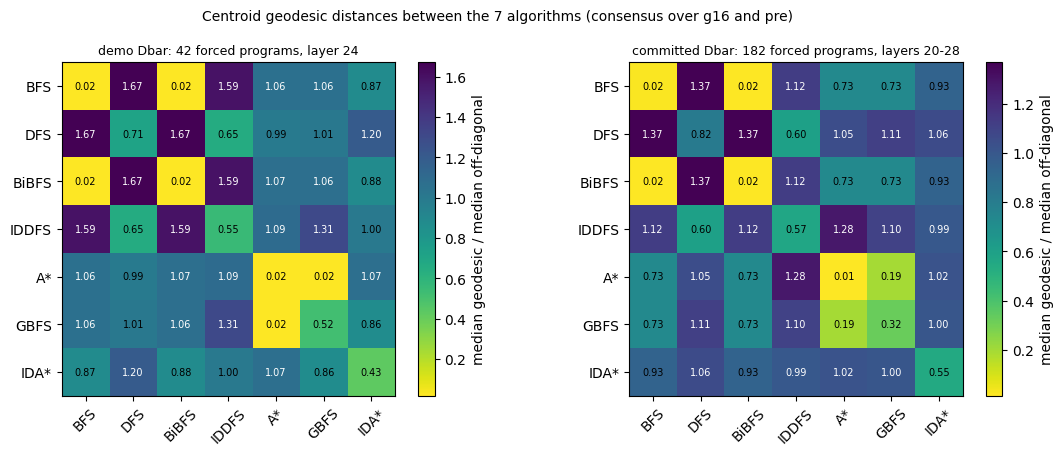

In [16]:
main("select")
geo_demo = read_json(RESULTS_DIR / "sets_and_geometry_demo.json")
geo_full = MD["sets_and_geometry"]  # committed: 182 forced programs, layers 20-28 x (g16, pre)
algs = geo_demo["algorithms"]
Dd, Df = np.array(geo_demo["Dbar"]), np.array(geo_full["Dbar"])
print("seriation path, demo     :", " - ".join(SHORT[a] for a in geo_demo["seriation_path"]))
print("seriation path, committed:", " - ".join(SHORT[a] for a in geo_full["seriation_path"]))
print("Held-Karp cost equals brute force:", geo_demo["held_karp_vs_bruteforce"]["match"])
rows_sets = []
for s, banned in geo_full["sets"].items():
    eo_d = edge_opposite(Dd, algs, banned)  # the committed banned set seen through the demo geometry
    rows_sets.append({"set": s, "banned (committed, sampled)": nm(banned), "demo selection": nm(geo_demo["sets"].get(s)),
                      "EDGE committed": nm(geo_full["edge_opposite"][s]["EDGE"]), "EDGE demo": nm(eo_d["EDGE"]),
                      "OPPOSITE committed": nm(geo_full["edge_opposite"][s]["OPPOSITE"]), "OPPOSITE demo": nm(eo_d["OPPOSITE"])})
display(pd.DataFrame(rows_sets))
print("program-bootstrap stability of the demo selection:", geo_demo["stability"]["bootstrap"])

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
for ax, (title, D) in zip(axes, [(f"demo Dbar: 42 forced programs, layer {LAYERS[0]}", Dd),
                                 ("committed Dbar: 182 forced programs, layers 20-28", Df)]):
    im = ax.imshow(D, cmap="viridis_r")
    ax.set_xticks(range(len(algs)), [SHORT[a] for a in algs], rotation=45)
    ax.set_yticks(range(len(algs)), [SHORT[a] for a in algs])
    for i in range(len(algs)):
        for j in range(len(algs)):
            ax.text(j, i, f"{D[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="w" if D[i, j] > np.median(D) else "k")
    ax.set_title(title, fontsize=9)
    fig.colorbar(im, ax=ax, fraction=0.046, label="median geodesic / median off-diagonal")
plt.suptitle("Centroid geodesic distances between the 7 algorithms (consensus over g16 and pre)", fontsize=10)
plt.tight_layout()
plt.show()

## S7 — Committed forecasts and the hash chain (`mb/forecasts.py`, `common.py`)

Before session 2 sampled any multi-ban, `stage_commit` turned the FRLP cells into six forecasts of where each set's programs would land among its survivors:

| Forecast | p_j ∝ |
|---|---|
| LADDER | exp(L^c_j(base)): the next default down the ladder |
| PRIME_AND_VETO | exp(L^c_j(base) + PV_j), PV_j = mean_w [L_j(mention_w) − L_j(neutral_w)] |
| PROXIMITY | softmax(−d(j, banned) / median Dbar): the survivor nearest the banned set |
| FRLP_BAN | mean_w exp(L^c_j(ban_w)): the likelihood under the ban prompt itself |
| GENERIC | exp(L^c_j(base) + u_j), u_j from the nonce ban ("the Zorblax method") |
| CORPUS | external naming counts (add-one smoothed) |

Each forecast is stored mixed: 0.93 × raw + 0.05 × uniform + 0.02 on "other". The FRLP mass of the banned algorithms under the ban prompts also gives an **implied avoidance**.

The forecasts, the multi-ban prompts and the sha256 of `analysis/landing.py` were appended to `commitments.log`. Every line stores the sha256 of its payload and of the previous line, so changing any payload or line breaks the chain.

The cell does two things:
- recomputes every forecast with the original code from the stored cells, and compares it with the committed copy;
- verifies the chain. The payload of line 0 (`prompts/frozen_prompts.json`, 0.95 MB) is not in the demo data, so that single payload check is expected to report it missing.

In [17]:
# mb/forecasts.py
PRED_DIR = ROOT / "predictions"


FORECASTS = ("LADDER", "PRIME_AND_VETO", "PROXIMITY", "FRLP_BAN", "GENERIC", "CORPUS")


def cells() -> list[dict[str, Any]]:
    return [r for r in read_jsonl(RESULTS_DIR / "frlp_cells.jsonl") if "variant" not in r]


def cell_index(rows: list[dict[str, Any]]) -> dict[tuple, dict[str, Any]]:
    """(task, condition, template, twin, algorithm, half) -> row (base cells have twin None)."""
    return {(r["task"], r["condition"], r["template"], r.get("twin"), r["algorithm"], r["half"]): r for r in rows}


def combine_halves(c1: dict[str, Any] | None, c2: dict[str, Any] | None) -> float | None:
    """Exact logmeanexp over the union of two halves from their per-half logmeanexps."""
    parts = [(c["L"], c["n_programs"]) for c in (c1, c2) if c is not None]
    if not parts:
        return None
    n = sum(k for _, k in parts)
    m = max(L for L, _ in parts)
    return m + math.log(sum(k * math.exp(L - m) for L, k in parts) / n)


def normalise(w: dict[str, float]) -> dict[str, float]:
    tot = sum(w.values())
    if not np.isfinite(tot) or tot <= 0:
        return {k: 1.0 / len(w) for k in w}
    return {k: v / tot for k, v in w.items()}


def softmax_log(x: dict[str, float]) -> dict[str, float]:
    m = max(x.values())
    return normalise({k: math.exp(v - m) for k, v in x.items()})


def mix(p: dict[str, float]) -> dict[str, float]:
    S = len(p)
    out = {k: (1 - THRESHOLDS["uniform_mix"] - THRESHOLDS["other_floor"]) * v + THRESHOLDS["uniform_mix"] / S
           for k, v in p.items()}
    out["other"] = THRESHOLDS["other_floor"]
    return out


def derived(set_name: str, plan: dict[str, Any], idx: dict[tuple, dict[str, Any]], Lc: dict[str, float],
            corr: dict[str, float]) -> dict[str, Any]:
    cname = f"multi:{set_name}"
    surv, banned = plan["survivors"], plan["banned"]
    tpls = [t["template"] for t in plan["templates"]]
    out: dict[str, Any] = {"G": {}, "G_h2": {}, "PV": {}, "PV_by_template": {}, "banned_drop": [], "L_ban_all": {}}
    for j in surv:
        g, gh2, pv, lb = [], [], [], []
        for w in tpls:
            b1, b2 = idx.get(("t1", cname, w, "ban", j, "h1")), idx.get(("t1", cname, w, "ban", j, "h2"))
            n1, n2 = idx.get(("t1", cname, w, "neutral", j, "h1")), idx.get(("t1", cname, w, "neutral", j, "h2"))
            m1 = idx.get(("t1", cname, w, "mention", j, "h1"))
            Lb, Ln = combine_halves(b1, b2), combine_halves(n1, n2)
            if Lb is not None and Ln is not None:
                g.append(Lb - Ln)
                lb.append(Lb)
            if b2 is not None and n2 is not None:
                gh2.append(b2["L"] - n2["L"])
            if m1 is not None and n1 is not None:
                pv.append(m1["L"] - n1["L"])
        out["G"][j] = float(np.mean(g)) if g else None
        out["G_h2"][j] = float(np.mean(gh2)) if gh2 else None
        out["PV"][j] = float(np.mean(pv)) if pv else None
        out["PV_by_template"][j] = pv
        out["L_ban_all"][j] = lb
    for b in banned:
        for t in plan["templates"]:
            w = t["template"]
            c, n = idx.get(("t1", cname, w, "ban", b, "h1")), idx.get(("t1", cname, w, "neutral", b, "h1"))
            if c is not None and n is not None:
                out["banned_drop"].append({"algorithm": b, "template": w, "drop": c["L"] - n["L"],
                                           "list_position": c.get("list_position"), "ess_ban": c["ess"]})
    # FRLP-implied avoidance (exp(L^c) ~ P(j | c))
    pb = {}
    for b in banned:
        vals = [idx[("t1", cname, t["template"], "ban", b, "h1")]["L"] + corr.get(b, 0.0) for t in plan["templates"]
                if ("t1", cname, t["template"], "ban", b, "h1") in idx]
        pb[b] = float(np.mean([math.exp(v) for v in vals])) if vals else 0.0
    ps = {j: float(np.mean([math.exp(v + corr.get(j, 0.0)) for v in out["L_ban_all"][j]])) if out["L_ban_all"][j]
          else 0.0 for j in surv}
    tot = sum(pb.values()) + sum(ps.values())
    out["frlp_implied_avoidance"] = (sum(ps.values()) / tot) if tot > 0 else None
    out["frlp_implied_banned_share"] = {b: v / tot for b, v in pb.items()} if tot > 0 else None
    out["frlp_mass_ban"] = {"survivors": ps, "banned": pb}
    return out


def generic_profile(idx: dict[tuple, dict[str, Any]], algs: list[str]) -> dict[str, float | None]:
    u = {}
    for j in algs:
        d = []
        for w in ("W1", "W2", "W3", "W4", "W5"):
            c, n = idx.get(("t1", "nonce", w, "ban", j, "h1")), idx.get(("t1", "nonce", w, "neutral", j, "h1"))
            if c is not None and n is not None:
                d.append(c["L"] - n["L"])
        u[j] = float(np.mean(d)) if d else None
    return u


RECOMPUTED: dict[str, Any] = {}  # notebook: recomputed forecast payloads, by set


def stage_commit() -> None:
    PRED_DIR.mkdir(exist_ok=True)
    geo = read_json(RESULTS_DIR / "sets_and_geometry.json")
    plan = read_json(RESULTS_DIR / "planned_conditions.json")
    rows = cells()
    idx = cell_index(rows)
    algs = geo["algorithms"]
    Lc = geo["L_base_corrected"]
    corr = {a: Lc[a] - geo["L_base_raw"][a] for a in algs}
    Dbar = np.array(geo["Dbar"])
    med = geo["median_offdiag"]
    u = generic_profile(idx, algs)
    aux = RESULTS_DIR / "aux_datasets.json"
    corpus = read_json(aux)["corpus_counts"]["t1"] if aux.exists() else {}
    landing_py = ROOT / "analysis" / "landing.py"
    assert landing_py.exists(), "analysis/landing.py must exist before the commit"
    payload_files = []
    summary = {}
    for set_name, p in plan["t1"].items():
        surv = p["survivors"]
        dv = derived(set_name, p, idx, Lc, corr)
        eo = geo["edge_opposite"].get(set_name) or {}
        dist = {j: float(min(Dbar[algs.index(j), algs.index(b)] for b in p["banned"])) for j in surv}
        f_raw = {
            "LADDER": softmax_log({j: Lc[j] for j in surv}),
            "PRIME_AND_VETO": softmax_log({j: Lc[j] + (dv["PV"][j] or 0.0) for j in surv}),
            "PROXIMITY": softmax_log({j: -dist[j] / med for j in surv}),
            "FRLP_BAN": normalise({j: dv["frlp_mass_ban"]["survivors"][j] for j in surv}),
            "GENERIC": softmax_log({j: Lc[j] + (u[j] or 0.0) for j in surv}),
        }
        if corpus:
            # addition beyond the plan: external popularity (add-one smoothed corpus naming counts)
            f_raw["CORPUS"] = normalise({j: corpus.get(j, 0) + 1.0 for j in surv})
        payload = {"set": set_name, "task": "t1", "banned": p["banned"], "survivors": surv,
                   "EDGE": eo.get("EDGE"), "OPPOSITE": eo.get("OPPOSITE"), "d_min": dist,
                   "PV_ranking": sorted(surv, key=lambda j: -(dv["PV"][j] if dv["PV"][j] is not None else -1e9)),
                   "forecasts_raw": f_raw, "forecasts_mixed": {k: mix(v) for k, v in f_raw.items()},
                   "top1": {k: max(v, key=v.get) for k, v in f_raw.items()},
                   "frlp_implied_avoidance": dv["frlp_implied_avoidance"],
                   "frlp_implied_banned_share": dv["frlp_implied_banned_share"],
                   "derived": {k: dv[k] for k in ("G", "G_h2", "PV", "PV_by_template", "banned_drop")},
                   "generic_u": {j: u[j] for j in surv}, "L_base_corrected": {j: Lc[j] for j in surv},
                   "prompts": {t["template"]: t["halves"]["1"]["prompts"]["ban"] for t in p["templates"]},
                   "analysis_landing_py_sha256": sha256_file(landing_py), "utc": utc_now()}
        fp = PRED_DIR / f"forecasts_{set_name}.json"
        # notebook: the committed forecast files are kept and nothing is re-committed; the recomputed payload is
        # collected for the comparison with the committed one (original: write_json(fp, payload))
        RECOMPUTED[set_name] = payload
        payload_files.append(fp)
        summary[set_name] = {"survivors": surv, "top1": payload["top1"], "EDGE": eo.get("EDGE"),
                             "OPPOSITE": eo.get("OPPOSITE"), "avoidance_implied": dv["frlp_implied_avoidance"]}
        logger.info(f"{set_name}: banned {p['banned']} survivors {surv}; top1 {payload['top1']}; implied avoidance "
                    f"{dv['frlp_implied_avoidance']}")
    # notebook: the original appends planned_conditions.json, the four forecasts and analysis/landing.py to
    # commitments.log here; the demo verifies the committed chain instead
    ok, probs = verify_chain()
    write_json(RESULTS_DIR / "commit_summary.json", {"sets": summary, "chain_ok": ok, "problems": probs,
                                                     "commit_log": str(COMMIT_LOG.name), "utc": utc_now()})
    logger.info(f"commit chain ok={ok} {probs}")

In [18]:
main("commit")
rows_fc = []
for s, fc in MD["forecasts"].items():
    rc = RECOMPUTED[s]
    same = (rc["top1"] == fc["top1"]
            and all(np.allclose([rc["forecasts_raw"][f][j] for j in fc["survivors"]],
                                [fc["forecasts_raw"][f][j] for j in fc["survivors"]], rtol=1e-9, atol=0)
                    for f in fc["forecasts_raw"])
            and math.isclose(rc["frlp_implied_avoidance"], fc["frlp_implied_avoidance"], rel_tol=1e-9))
    rows_fc.append({"set": s, "banned": nm(fc["banned"]), "survivors": nm(fc["survivors"]),
                    **{f"top-1 {f}": SHORT[rc["top1"][f]] for f in FORECASTS if f in rc["top1"]},
                    "implied avoidance": f"{rc['frlp_implied_avoidance']:.2g}", "recomputed == committed": same})
display(pd.DataFrame(rows_fc))
cs = read_json(RESULTS_DIR / "commit_summary.json")
print(f"hash chain verified: {cs['chain_ok']}; problems: {cs['problems']}")
for ln in MD["commitments_log"]:
    e = json.loads(ln)
    print(f"  line {e['i']}  {e['utc_time'][:19]}Z  {e['payload_path']:<33} payload {e['payload_sha256'][:12]}..."
          f"  prev line {e['prev_line_sha256'][:12]}...")

10:10:15|INFO   |TOP: banned ['bfs', 'dfs', 'gbfs', 'iddfs'] survivors ['bibfs', 'astar', 'idastar']; top1 {'LADDER': 'astar', 'PRIME_AND_VETO': 'bibfs', 'PROXIMITY': 'bibfs', 'FRLP_BAN': 'astar', 'GENERIC': 'astar', 'CORPUS': 'astar'}; implied avoidance 3.013920384876042e-14


10:10:15|INFO   |ARC: banned ['bfs', 'bibfs', 'astar', 'gbfs'] survivors ['dfs', 'iddfs', 'idastar']; top1 {'LADDER': 'dfs', 'PRIME_AND_VETO': 'dfs', 'PROXIMITY': 'idastar', 'FRLP_BAN': 'dfs', 'GENERIC': 'dfs', 'CORPUS': 'dfs'}; implied avoidance 0.9994862398727997


10:10:15|INFO   |SCATTER: banned ['bfs', 'dfs', 'gbfs', 'idastar'] survivors ['bibfs', 'iddfs', 'astar']; top1 {'LADDER': 'iddfs', 'PRIME_AND_VETO': 'astar', 'PROXIMITY': 'bibfs', 'FRLP_BAN': 'iddfs', 'GENERIC': 'iddfs', 'CORPUS': 'astar'}; implied avoidance 8.802088694771974e-09


10:10:15|INFO   |TOP5: banned ['bfs', 'dfs', 'gbfs', 'iddfs', 'astar'] survivors ['bibfs', 'idastar']; top1 {'LADDER': 'bibfs', 'PRIME_AND_VETO': 'bibfs', 'PROXIMITY': 'bibfs', 'FRLP_BAN': 'bibfs', 'GENERIC': 'bibfs', 'CORPUS': 'bibfs'}; implied avoidance 1.7424650072987964e-18


10:10:15|INFO   |commit chain ok=False ['line 0: payload missing prompts/frozen_prompts.json']


10:10:15|INFO   |stage commit done in 0.0s


,set,banned,survivors,top-1 LADDER,top-1 PRIME_AND_VETO,top-1 PROXIMITY,top-1 FRLP_BAN,top-1 GENERIC,top-1 CORPUS,implied avoidance,recomputed == committed
0,ARC,"BFS, BiBFS, A*, GBFS","DFS, IDDFS, IDA*",DFS,DFS,IDA*,DFS,DFS,DFS,1,True
1,SCATTER,"BFS, DFS, GBFS, IDA*","BiBFS, IDDFS, A*",IDDFS,A*,BiBFS,IDDFS,IDDFS,A*,8.8e-09,True
2,TOP,"BFS, DFS, GBFS, IDDFS","BiBFS, A*, IDA*",A*,BiBFS,BiBFS,A*,A*,A*,3e-14,True
3,TOP5,"BFS, DFS, GBFS, IDDFS, A*","BiBFS, IDA*",BiBFS,BiBFS,BiBFS,BiBFS,BiBFS,BiBFS,1.7e-18,True


hash chain verified: False; problems: ['line 0: payload missing prompts/frozen_prompts.json']
  line 0  2026-10-20T01:49:35Z  prompts/frozen_prompts.json       payload 1776dc23c33c...  prev line 000000000000...
  line 1  2026-10-20T03:28:35Z  results/planned_conditions.json   payload b1b55622ffa9...  prev line a56402c2f1b0...
  line 2  2026-10-20T03:28:35Z  predictions/forecasts_TOP.json    payload 7aa3f9ec53db...  prev line 9d191dec07c4...
  line 3  2026-10-20T03:28:36Z  predictions/forecasts_ARC.json    payload a1dc8f9f460c...  prev line c6b811f6e6c4...
  line 4  2026-10-20T03:28:36Z  predictions/forecasts_SCATTER.json payload b998c64f823a...  prev line f76399207b01...
  line 5  2026-10-20T03:28:36Z  predictions/forecasts_TOP5.json   payload ee3302373b37...  prev line 3a84a5c391d1...
  line 6  2026-10-20T03:28:36Z  analysis/landing.py               payload deafefdf61bf...  prev line b83c6fca605e...


## S8–S9 — Session 2 and its states (GPU; not re-run)

Session 2 sampled TOP, ARC, SCATTER and TOP5 (W1–W5 × 20 each) only after the commit. Stage 2 of the HF scoring then teacher-forced every session-2 program under the name-free baseline prompt. This puts the sampled programs in the same activation coordinates as the forced ones (`states/t1/base`). The 40 multi-ban programs of the demo data (2 per template and set) carry those states.

## S10 — Behaviour and landing tests (`analysis/landing.py`, committed before session 2)

Per condition, `summarise` reports:
- the landing distribution of attempted programs over {each survivor, banned (by algorithm), other};
- **avoidance** = 1 − banned share, with a Wilson 95% interval and a template-cluster bootstrap;
- the **gate**: avoidance ≥ 0.5 and ≥ 20 non-banned programs.

`disguise` counts the banned-mechanism programs whose response never names their own mechanism.

The **landing tests** compare the realised survivor shares with every committed forecast:
- S_edge = share(EDGE) − share(OPPOSITE);
- Spearman ρ;
- exact survivor-permutation nulls, pooled over sets with the exact product null;
- log scores against uniform, and top-1 hits.

The dry run checks the nulls on planted data. The code is the committed script, except that the T2 leave-one-survivor part (`run_los`) is dropped because T2 is not in the demo data. With 10 programs per condition the demo shares are coarse, so the full-run values are shown alongside.

In [19]:
# analysis/landing.py (the committed script)
FORECASTS = ("LADDER", "PRIME_AND_VETO", "PROXIMITY", "FRLP_BAN", "GENERIC", "CORPUS")


# N_BOOT = 2000  # notebook: set in the config cell


# notebook: landing.py's UNRESOLVED (it shadows the labeller's UNRESOLVED of the S3 cell from here on)
UNRESOLVED = ("unknown", "no_code", "inconsistent")


SELF_NAME_RE = re.compile(r"\b(backtrack\w*|flood[\s_-]?fill\w*|wave[\s_-]?front|level[\s_-]?order|breadth[\s_-]?first|"
                          r"depth[\s_-]?first|best[\s_-]?first|greedy|heuristic|a\*|a[\s_-]?star|dijkstra|bfs|dfs|"
                          r"iddfs|ida\*|bidirectional|bellman[\s_-]?ford|spfa|floyd|dial|bucket|priority[\s_-]?queue|"
                          r"recursive|stack[\s_-]?based|queue[\s_-]?based|random[\s_-]?walk|wall[\s_-]?follow\w*|"
                          r"spiral|brute[\s_-]?force|exhaustive|depth[\s_-]?limited|iterative[\s_-]?deepening|"
                          r"label[\s_-]?correcting|relaxation|memoi[sz]\w*|dynamic[\s_-]?programming)\b", re.I)


# ------------------------------------------------------------------------------------------------ statistics
def spearman(x: list[float], y: list[float]) -> float | None:
    from scipy.stats import spearmanr

    if len(x) < 2 or len(set(x)) < 2 or len(set(y)) < 2:
        return None
    r = spearmanr(x, y).statistic
    return None if r is None or not np.isfinite(r) else float(r)


def perm_null(values: list[float], stat, observed: float) -> dict[str, Any]:
    """Exact survivor-permutation null: permute the realised survivor values over all S! assignments."""
    perms = list(itertools.permutations(values))
    dist = [stat(list(p)) for p in perms]
    dist = [d for d in dist if d is not None]
    if observed is None or not dist:
        return {"p": None, "n_perm": len(perms)}
    p = sum(1 for d in dist if d >= observed - 1e-12) / len(dist)
    return {"p": p, "n_perm": len(perms), "null_mean": float(np.mean(dist))}


def product_null(per_set: list[tuple[list[float], Any, float]]) -> dict[str, Any]:
    """Pooled exact product null: sum of per-set statistics over the product of the per-set permutation sets."""
    dists = []
    obs = 0.0
    for vals, stat, o in per_set:
        d = [stat(list(p)) for p in itertools.permutations(vals)]
        d = [x for x in d if x is not None]
        if o is None or not d:
            continue
        dists.append(d)
        obs += o
    if not dists:
        return {"p": None}
    tot = np.zeros(1)
    for d in dists:
        tot = (tot[:, None] + np.array(d)[None, :]).ravel()
    return {"p": float((tot >= obs - 1e-12).mean()), "n": int(tot.size), "observed_sum": obs}


def logscore(probs: dict[str, float], labels: list[str]) -> float:
    return float(np.mean([math.log(max(probs.get(y, probs.get("other", 1e-9)), 1e-12)) for y in labels])) if labels else float("nan")


# ------------------------------------------------------------------------------------------------ landing per condition
def landing_category(label: str, banned: list[str], catalogue: list[str]) -> str:
    if label in banned:
        return "banned:" + label
    if label in catalogue:
        return label
    return "other"


def summarise(rows: list[dict[str, Any]], banned: list[str], catalogue: list[str], survivors: list[str],
              rng: np.random.Generator) -> dict[str, Any]:
    n_all = len(rows)
    att = [r for r in rows if r.get("label") not in UNRESOLVED and r.get("code")]
    cats = [landing_category(r["label"], banned, catalogue) for r in att]
    cnt = collections.Counter(cats)
    n = len(att)
    nb = sum(v for k, v in cnt.items() if k.startswith("banned:"))
    nonb = n - nb
    avoid = 1 - nb / n if n else None
    comp = sum(1 for r, c in zip(att, cats) if r.get("passed") and not c.startswith("banned:"))
    out = {"n_samples": n_all, "attempted": n, "unknown_rate": (n_all - n) / max(n_all, 1),
           "truncation_rate": sum(1 for r in rows if r.get("truncated")) / max(n_all, 1),
           "counts": dict(cnt), "fine_labels": dict(collections.Counter(r["label"] for r in rows)),
           "shares": {k: v / n for k, v in cnt.items()} if n else {},
           "share_ci": {k: wilson_ci(v, n) for k, v in cnt.items()},
           "avoidance": avoid, "avoidance_ci": wilson_ci(nonb, n) if n else None,
           "n_nonbanned": nonb, "compliant_share": comp / max(n_all, 1), "compliant_ci": wilson_ci(comp, n_all),
           "gate": bool(avoid is not None and avoid >= THRESHOLDS["gate_avoidance"]
                        and nonb >= THRESHOLDS["gate_min_nonbanned"]),
           "pass_rate_attempted": sum(1 for r in att if r.get("passed")) / max(n, 1)}
    surv_counts = {s: cnt.get(s, 0) for s in survivors}
    tot_s = sum(surv_counts.values())
    out["survivor_counts"] = surv_counts
    out["survivor_shares"] = {s: v / tot_s for s, v in surv_counts.items()} if tot_s else {s: None for s in survivors}
    # per-template table + template-cluster bootstrap
    by_t = collections.defaultdict(list)
    for r in rows:
        by_t[r["template"]].append(r)
    out["per_template"] = {}
    for t, rs in sorted(by_t.items()):
        a = [r for r in rs if r.get("label") not in UNRESOLVED and r.get("code")]
        c = collections.Counter(landing_category(r["label"], banned, catalogue) for r in a)
        out["per_template"][t] = {"n": len(rs), "attempted": len(a), "counts": dict(c),
                                  "avoidance": 1 - sum(v for k, v in c.items() if k.startswith("banned:")) / len(a)
                                  if a else None}
    tkeys = sorted(by_t)
    boots = collections.defaultdict(list)
    for _ in range(N_BOOT):
        pick = rng.choice(len(tkeys), size=len(tkeys), replace=True)
        rs = [r for i in pick for r in by_t[tkeys[i]]]
        a = [r for r in rs if r.get("label") not in UNRESOLVED and r.get("code")]
        if not a:
            continue
        c = collections.Counter(landing_category(r["label"], banned, catalogue) for r in a)
        nbb = sum(v for k, v in c.items() if k.startswith("banned:"))
        boots["avoidance"].append(1 - nbb / len(a))
        ts = sum(c.get(s, 0) for s in survivors)
        for s in survivors:
            boots[f"surv_share:{s}"].append(c.get(s, 0) / ts if ts else np.nan)
        for k in set(cats) | {"other"}:
            boots[f"share:{k}"].append(c.get(k, 0) / len(a))
    out["cluster_bootstrap_ci"] = {k: [float(np.nanpercentile(v, 2.5)), float(np.nanpercentile(v, 97.5))]
                                   for k, v in boots.items() if len(v) and not np.all(np.isnan(v))}
    return out


def names_own_mechanism(text: str, label: str) -> bool:
    fams = MECH_ALIAS_FAMILIES.get(label, [])
    low = text.lower()
    for f in fams:
        for a in ALIASES[f]:
            if a.endswith("*"):
                if re.search(r"(?<![a-z0-9_])" + re.escape(a), low):
                    return True
            elif a in low or a.replace(" ", "_") in low or a.replace("-", "_") in low:
                return True
    return False


def self_names(row: dict[str, Any]) -> list[str]:
    names = re.findall(r"def\s+([A-Za-z_][A-Za-z0-9_]*)", row.get("code") or "")
    words = [m.group(0).lower() for m in SELF_NAME_RE.finditer(row.get("text") or "")]
    return sorted(set(n for n in names if n != "solve")) + sorted(set(words))


def disguise(rows: list[dict[str, Any]], banned: list[str]) -> dict[str, Any]:
    br = [r for r in rows if r.get("label") in banned]
    dis = [r for r in br if not names_own_mechanism(r.get("text") or "", r["label"])]
    names = collections.Counter(n for r in dis for n in self_names(r))
    return {"n_banned_mechanism": len(br), "n_disguised": len(dis),
            "disguise_rate": len(dis) / len(br) if br else None,
            "by_mechanism": {b: {"n": sum(1 for r in br if r["label"] == b),
                                 "disguised": sum(1 for r in dis if r["label"] == b)} for b in banned},
            "self_names_top": names.most_common(15)}


# ------------------------------------------------------------------------------------------------ landing tests
def landing_tests(fc: dict[str, Any], summ: dict[str, Any], rows: list[dict[str, Any]], catalogue: list[str],
                  likelihood: dict[str, Any] | None) -> dict[str, Any]:
    surv = fc["survivors"]
    shares = [summ["survivor_shares"].get(s) for s in surv]
    out: dict[str, Any] = {"survivors": surv, "survivor_shares": dict(zip(surv, shares)),
                           "n_landed_survivor": sum(summ["survivor_counts"].values())}
    if any(s is None for s in shares) or len(surv) < 2:
        out["note"] = "no landed survivor mass (or < 2 survivors): rank tests undefined"
        return out
    edge, opp = fc.get("EDGE") or [], fc.get("OPPOSITE") or []

    def s_edge(vals: list[float]) -> float:
        m = dict(zip(surv, vals))
        return sum(m[e] for e in edge) - sum(m[o] for o in opp)

    obs = s_edge(shares)
    out["S_edge"] = {"observed": obs, **perm_null(shares, s_edge, obs), "EDGE": edge, "OPPOSITE": opp}
    out["rho"] = {}
    for f in FORECASTS:
        if f not in fc["forecasts_raw"]:
            continue
        pred = [fc["forecasts_raw"][f][s] for s in surv]
        st = (lambda v, pred=pred: spearman(pred, v))
        r = st(shares)
        out["rho"][f] = {"observed": r, **perm_null(shares, st, r)}
    # log scores of committed mixed forecasts vs uniform (non-banned attempted programs)
    banned = fc["banned"]
    labs = [landing_category(r["label"], banned, catalogue) for r in rows
            if r.get("label") not in UNRESOLVED and r.get("code")]
    labs = [y for y in labs if not y.startswith("banned:")]
    S = len(surv)
    uni = {s: (1 - THRESHOLDS["other_floor"]) / S for s in surv}
    uni["other"] = THRESHOLDS["other_floor"]
    out["log_score"] = {"n": len(labs), "uniform": logscore(uni, labs)}
    modal = collections.Counter(y for y in labs if y in surv).most_common(1)
    for f in FORECASTS:
        if f not in fc["forecasts_mixed"]:
            continue
        ls = logscore(fc["forecasts_mixed"][f], labs)
        out["log_score"][f] = {"mean": ls, "minus_uniform": ls - out["log_score"]["uniform"],
                               "top1": fc["top1"][f], "top1_hit": bool(modal and fc["top1"][f] == modal[0][0])}
    out["realised_top1"] = modal[0][0] if modal else None
    if likelihood is not None:
        g = likelihood.get("G_h2") or {}
        pv = likelihood.get("PV") or {}
        if all(g.get(s) is not None for s in surv) and all(pv.get(s) is not None for s in surv):
            gv = [g[s] for s in surv]
            st = (lambda v: spearman([pv[s] for s in surv], v))
            r = st(gv)
            out["likelihood_landing"] = {"G_h2": g, "PV_h1": pv, "rho_PV": {"observed": r, **perm_null(gv, st, r)}}
    return out


# ------------------------------------------------------------------------------------------------ dry run (T7)
def dry_run() -> dict[str, Any]:
    rng = np.random.default_rng(7)
    surv = ["a", "b", "c", "d", "e"]
    edge, opp = ["a", "b"], ["d", "e"]

    def s_edge(v):
        m = dict(zip(surv, v))
        return m["a"] + m["b"] - m["d"] - m["e"]

    planted = [0.4, 0.3, 0.15, 0.1, 0.05]
    r = perm_null(planted, s_edge, s_edge(planted))
    ps = []
    for _ in range(DRY_RUN_REPS):  # notebook: config cell (original: 200)
        c = rng.multinomial(60, [0.2] * 5)
        v = list(c / c.sum())
        ps.append(perm_null(v, s_edge, s_edge(v))["p"])
    ls = logscore({"a": 0.5, "b": 0.5, "other": 0.0}, ["a", "a", "b"])
    pooled = product_null([(planted, s_edge, s_edge(planted))] * 3)
    return {"planted_edge_p": r["p"], "n_perm": r["n_perm"], "uniform_p_mean": float(np.mean(ps)),
            "uniform_p_le_0.05": float(np.mean(np.array(ps) <= 0.05)), "logscore_check": ls,
            "logscore_expected": math.log(0.5), "pooled_planted_p": pooled["p"], "pooled_n": pooled["n"]}


# ------------------------------------------------------------------------------------------------ main
def run_landing() -> None:
    rng = np.random.default_rng(20261020)
    keep = read_json(RESULTS_DIR / "catalogue_keep.json")
    cat_t1 = keep.get("analysis_catalogue_final", keep["analysis_catalogue"])["t1"]
    cat_t2 = MODES["t2"]
    out: dict[str, Any] = {"dry_run": dry_run(), "catalogue_t1": cat_t1, "conditions": {}, "tests": {}}
    s1 = read_jsonl(DATA_DIR / "labelled_session1.jsonl")
    s2 = read_jsonl(DATA_DIR / "labelled_session2.jsonl") if (DATA_DIR / "labelled_session2.jsonl").exists() else []
    # references and baselines
    for task, cond, banned, cat in (("t1", "baseline", [], cat_t1), ("t2", "baseline", [], cat_t2),
                                    ("t1", "single:bfs", ["bfs"], cat_t1), ("t2", "single:dijkstra", ["dijkstra"], cat_t2)):
        rows = [r for r in s1 if r["task"] == task and r["condition"] == cond]
        surv = [a for a in cat if a not in banned]
        out["conditions"][f"{task}|{cond}"] = {"banned": banned, **summarise(rows, banned, cat, surv, rng),
                                               "disguise": disguise(rows, banned)}
    # multi-bans
    pooled_inputs: dict[str, list] = collections.defaultdict(list)
    for fp in sorted((ROOT / "predictions").glob("forecasts_*.json")):
        fc = read_json(fp)
        s = fc["set"]
        rows = [r for r in s2 if r["condition"] == f"multi:{s}"]
        summ = summarise(rows, fc["banned"], cat_t1, fc["survivors"], rng)
        out["conditions"][f"t1|multi:{s}"] = {"banned": fc["banned"], "survivors": fc["survivors"], **summ,
                                              "disguise": disguise(rows, fc["banned"]),
                                              "frlp_implied_avoidance": fc.get("frlp_implied_avoidance")}
        lt = landing_tests(fc, summ, rows, cat_t1, fc.get("derived"))
        lt["gate"] = summ["gate"]
        lt["gate_note"] = None if summ["gate"] else "gate failed (avoidance < 0.5 or < 20 non-banned): flagged"
        out["tests"][s] = lt
        if "S_edge" in lt:
            sh = [lt["survivor_shares"][x] for x in fc["survivors"]]
            surv = fc["survivors"]

            def s_edge(v, surv=surv, e=lt["S_edge"]["EDGE"], o=lt["S_edge"]["OPPOSITE"]):
                m = dict(zip(surv, v))
                return sum(m[x] for x in e) - sum(m[x] for x in o)

            pooled_inputs["S_edge"].append((sh, s_edge, lt["S_edge"]["observed"]))
            for f in FORECASTS:
                if f not in fc["forecasts_raw"]:
                    continue
                pred = [fc["forecasts_raw"][f][x] for x in surv]
                pooled_inputs[f"rho:{f}"].append((sh, (lambda v, pred=pred: spearman(pred, v)),
                                                  lt["rho"][f]["observed"]))
    out["pooled"] = {k: product_null(v) for k, v in pooled_inputs.items()}
    out["pooled"]["n_sets"] = {k: len(v) for k, v in pooled_inputs.items()}
    # references contrasted with TOP
    if "TOP" in out["tests"]:
        out["reference_contrast"] = {
            "t1_single_bfs": out["conditions"]["t1|single:bfs"]["counts"],
            "t2_single_dijkstra": out["conditions"]["t2|single:dijkstra"]["counts"],
            "t1_TOP": out["conditions"].get("t1|multi:TOP", {}).get("counts")}
    write_json(RESULTS_DIR / "landing.json", out)
    # notebook: run_los(s1, rng), the T2 leave-one-survivor analysis, needs the T2 programs (not in the demo data)
    logger.info(f"landing written: {list(out['tests'].keys())}")

In [20]:
main("landing")
landing = read_json(RESULTS_DIR / "landing.json")
ref_land = MD["full_run_reference"]["landing_conditions"]
CONDS = ["t1|baseline", "t1|single:bfs", "t1|multi:TOP", "t1|multi:ARC", "t1|multi:SCATTER", "t1|multi:TOP5"]


def fmt_counts(cnt: dict[str, int]) -> str:
    return ", ".join(f"{SHORT.get(k.replace('banned:', ''), k)}{'*' if k.startswith('banned:') else ''} {v}"
                     for k, v in sorted(cnt.items(), key=lambda kv: -kv[1]))


def fmt_av(c: dict[str, Any], banned: list[str]) -> str:
    if not banned:
        return "-"
    lo, hi = c["avoidance_ci"]
    return f"{c['avoidance']:.2f} [{lo:.2f}, {hi:.2f}]"


def rnd(x: float | None) -> float | str:
    return "-" if x is None else round(x, 2)


tab = []
for k in CONDS:
    c, f = landing["conditions"][k], ref_land[k]
    tab.append({"condition": k.split("|")[1], "banned": nm(c["banned"]), "demo n": c["attempted"],
                "demo landing (* = banned)": fmt_counts(c["counts"]), "demo avoidance [95% CI]": fmt_av(c, c["banned"]),
                "demo gate": c["gate"] if c["banned"] else "-", "demo disguised": rnd(c["disguise"]["disguise_rate"]),
                "full n": f["attempted"], "full landing": fmt_counts(f["counts"]),
                "full avoidance [95% CI]": fmt_av(f, c["banned"]), "full disguised": rnd(f["disguise_rate"])})
display(pd.DataFrame(tab))
names = collections.Counter()
for k in CONDS[2:]:
    for n, v in landing["conditions"][k]["disguise"]["self_names_top"]:
        names[n] += v
print("what the disguised banned-mechanism programs call themselves (demo multi-bans):", names.most_common(8))
print("dry run on planted data:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in landing["dry_run"].items()})
for s, t in landing["tests"].items():
    ls = {f: round(v["minus_uniform"], 2) for f, v in t.get("log_score", {}).items() if isinstance(v, dict)}
    print(f"{s:<8} landed survivor programs: {t['n_landed_survivor']:>2}; realised top-1: {t.get('realised_top1')}; "
          f"log score - uniform: {ls if ls else '-'} {t.get('note', '')}")

10:10:15|INFO   |landing written: ['ARC', 'SCATTER', 'TOP', 'TOP5']


10:10:15|INFO   |stage landing done in 0.2s


,condition,banned,demo n,demo landing (* = banned),demo avoidance [95% CI],demo gate,demo disguised,full n,full landing,full avoidance [95% CI],full disguised
0,baseline,-,8,BFS 8,-,-,-,100,BFS 100,-,-
1,single:bfs,BFS,10,"DFS 9, BFS* 1","0.90 [0.60, 0.98]",False,1.0,100,"DFS 86, BFS* 14","0.86 [0.78, 0.91]",1.0
2,multi:TOP,"BFS, DFS, GBFS, IDDFS",10,"BFS* 5, DFS* 3, GBFS* 1, other 1","0.10 [0.02, 0.40]",False,0.78,100,"BFS* 59, DFS* 26, other 13, GBFS* 2","0.13 [0.08, 0.21]",0.51
3,multi:ARC,"BFS, BiBFS, A*, GBFS",10,"BFS* 8, DFS 2","0.20 [0.06, 0.51]",False,0.75,100,"BFS* 63, DFS 37","0.37 [0.28, 0.47]",0.92
4,multi:SCATTER,"BFS, DFS, GBFS, IDA*",10,"BFS* 7, DFS* 3","0.00 [0.00, 0.28]",False,0.8,100,"BFS* 69, DFS* 27, other 2, A* 2","0.04 [0.02, 0.10]",0.51
5,multi:TOP5,"BFS, DFS, GBFS, IDDFS, A*",10,"BFS* 7, DFS* 3","0.00 [0.00, 0.28]",False,0.5,100,"BFS* 63, DFS* 36, IDDFS* 1","0.00 [0.00, 0.04]",0.41


what the disguised banned-mechanism programs call themselves (demo multi-bans): [('backtrack', 8), ('is_valid', 6), ('heuristic', 1), ('priority queue', 1), ('find_path', 1)]
dry run on planted data: {'planted_edge_p': 0.0333, 'n_perm': 120, 'uniform_p_mean': 0.5345, 'uniform_p_le_0.05': 0.015, 'logscore_check': -0.6931, 'logscore_expected': -0.6931, 'pooled_planted_p': 0.0, 'pooled_n': 1728000}
ARC      landed survivor programs:  2; realised top-1: dfs; log score - uniform: {'LADDER': 1.06, 'PRIME_AND_VETO': 1.06, 'PROXIMITY': -0.02, 'FRLP_BAN': 1.06, 'GENERIC': 1.06, 'CORPUS': 1.06} 
SCATTER  landed survivor programs:  0; realised top-1: None; log score - uniform: - no landed survivor mass (or < 2 survivors): rank tests undefined
TOP      landed survivor programs:  0; realised top-1: None; log score - uniform: - no landed survivor mass (or < 2 survivors): rank tests undefined
TOP5     landed survivor programs:  0; realised top-1: None; log score - uniform: - no landed survivor mass (

## S11 — The activation-space manifold (`analysis/manifold.py`)

This is the geometry behind the landing question.
- **`geometry_sweep`** recomputes, for every (k, position) setting, the centroid geodesic matrix, its SMACOF metric MDS with Kruskal stress-1, and each algorithm's nearest neighbour. It then bootstraps the programs to test how stable those neighbours are.
- **`isomap_layout`** fits Isomap (k = 10) on the forced programs and places the sampled (natural) programs with `transform()`.
- **`persistence`** tests for a loop (persistent H1, with `ripser`) against a label-shuffled null and a covariance-matched Gaussian null. A circular manifold would make "the opposite side" well defined; the full run found no loop.

How to read each manifold panel:
- grey dots: forced programs;
- red crosses: the condition's sampled programs;
- coloured discs: algorithm centroids, sized and coloured by how many of the condition's programs implement that algorithm;
- black crosses: banned algorithms;
- blue arrow: from the mean of the banned centroids to the landing-weighted survivor centroid.

The within-ban probes (logistic probes on the `own` context) need states that are not in the demo data, so they are not run.

In [21]:
# analysis/manifold.py
POS = {"g8": 0, "g16": 1, "g32": 2, "pre": 3}


PRIMARY = {"layer": 24, "pos": "pre", "k": 10}


# K_SWEEP = (5, 10, 15, 20)  # notebook: set in the config cell


CMAP = "viridis"


def _states(task: str, context: str) -> dict[str, Any]:
    # notebook: load_states (mb/score.py) is defined in the data-layout cell
    return load_states(task, context)


def forced_points(task: str, algs: list[str]) -> tuple[np.ndarray, np.ndarray, list[dict[str, Any]]]:
    st = _states(task, "base")
    keep = [i for i, m in enumerate(st["meta"]) if m.get("kind") == "forced" and m.get("algorithm") in algs]
    return st["X"][keep].astype(np.float32), np.array([st["meta"][i]["algorithm"] for i in keep]), \
        [st["meta"][i] for i in keep]


def natural_points(task: str, context: str = "base") -> tuple[np.ndarray, list[dict[str, Any]]]:
    st = _states(task, context)
    keep = [i for i, m in enumerate(st["meta"]) if m.get("kind") == "natural"]
    return st["X"][keep].astype(np.float32), [st["meta"][i] for i in keep]


def pca_fit(Y: np.ndarray, n: int = 50) -> tuple[np.ndarray, np.ndarray]:
    mu = Y.mean(axis=0, keepdims=True)
    _, _, Vt = np.linalg.svd(Y - mu, full_matrices=False)
    return mu, Vt[:min(n, Vt.shape[0])]


def stress1(D: np.ndarray, Z: np.ndarray) -> float:
    from scipy.spatial.distance import pdist, squareform

    E = squareform(pdist(Z))
    iu = np.triu_indices_from(D, 1)
    return float(math.sqrt(((D[iu] - E[iu]) ** 2).sum() / (D[iu] ** 2).sum()))


def mds2(D: np.ndarray) -> tuple[np.ndarray, float]:
    from sklearn.manifold import MDS

    m = MDS(n_components=2, dissimilarity="precomputed", n_init=MDS_N_INIT, random_state=0, normalized_stress=False)
    Z = m.fit_transform(D)
    return Z, stress1(D, Z)


def nn_rank(D: np.ndarray, algs: list[str]) -> dict[str, list[str]]:
    out = {}
    for i, a in enumerate(algs):
        order = [algs[j] for j in np.argsort(D[i]) if j != i]
        out[a] = order
    return out


# ------------------------------------------------------------------------------------------------ geometry sweep
def geometry_sweep(task: str, algs: list[str]) -> dict[str, Any]:
    # notebook: centroid_matrix and knn_geodesic (mb/sets.py) are defined in the S6 cell
    X, lab, _ = forced_points(task, algs)
    res: dict[str, Any] = {"algorithms": algs, "n_points": int(len(lab)), "settings": []}
    nn_ref = None
    Dref = None
    for li, l in enumerate(LAYERS):
        for pos in [p for p in ("g16", "pre", "g8", "g32") if p in POSITIONS]:  # notebook: positions in the demo data
            Y = X[:, li, POS[pos], :]
            ok = ~np.isnan(Y).any(axis=1)
            mu, V = pca_fit(Y[ok])
            Z = (Y[ok] - mu) @ V.T
            for k in K_SWEEP if pos in ("g16", "pre") else (10,):
                G, info = knn_geodesic(Z, k)
                D = centroid_matrix(G, lab[ok], algs)
                _, st = mds2(D)
                nn = nn_rank(D, algs)
                row = {"layer": l, "position": pos, "k": k, "stress1": st, "bridges": info["bridges"],
                       "nearest": {a: nn[a][0] for a in algs}, "D": D}
                res["settings"].append(row)
                if l == PRIMARY["layer"] and pos == PRIMARY["pos"] and k == PRIMARY["k"]:
                    nn_ref, Dref = nn, D
    agree = [np.mean([s["nearest"][a] == nn_ref[a][0] for a in algs]) for s in res["settings"]]
    res["nearest_neighbour_stability_vs_primary"] = float(np.mean(agree))
    res["primary_D"] = Dref
    # program bootstrap at the primary setting
    li = LAYERS.index(PRIMARY["layer"])
    Y = X[:, li, POS[PRIMARY["pos"]], :]
    ok = ~np.isnan(Y).any(axis=1)
    mu, V = pca_fit(Y[ok])
    Z = (Y[ok] - mu) @ V.T
    G, _ = knn_geodesic(Z, PRIMARY["k"])
    rng = np.random.default_rng(0)
    labs = lab[ok]
    same = []
    for _ in range(GEO_BOOT):  # notebook: config cell (original: 200)
        sel = {a: rng.choice(np.where(labs == a)[0], size=(labs == a).sum(), replace=True) for a in algs}
        Db = centroid_matrix(G, labs, algs, sel)
        nb = nn_rank(Db, algs)
        same.append(np.mean([nb[a][0] == nn_ref[a][0] for a in algs]))
    res["bootstrap_nearest_same"] = float(np.mean(same))
    res["primary_nearest"] = {a: nn_ref[a][:3] for a in algs}
    return res


# ------------------------------------------------------------------------------------------------ figures
def isomap_layout(task: str, algs: list[str]) -> dict[str, Any]:
    from sklearn.manifold import Isomap

    X, lab, _ = forced_points(task, algs)
    li = LAYERS.index(PRIMARY["layer"])
    Y = X[:, li, POS[PRIMARY["pos"]], :]
    ok = ~np.isnan(Y).any(axis=1)
    mu, V = pca_fit(Y[ok])
    Z = (Y[ok] - mu) @ V.T
    iso = Isomap(n_neighbors=PRIMARY["k"], n_components=2)
    P = iso.fit_transform(Z)
    Xn, meta = natural_points(task, "base")
    Yn = Xn[:, li, POS[PRIMARY["pos"]], :]
    okn = ~np.isnan(Yn).any(axis=1)
    Pn = np.full((len(meta), 2), np.nan)
    if okn.any():
        Pn[okn] = iso.transform((Yn[okn] - mu) @ V.T)
    cent = {a: P[lab[ok] == a].mean(axis=0) for a in algs}
    return {"P": P, "lab": lab[ok], "Pn": Pn, "meta": meta, "cent": cent,
            "recon_error": float(iso.reconstruction_error())}


def fig_manifold(task: str, algs: list[str], lay: dict[str, Any], conds: list[tuple[str, list[str]]]) -> list[str]:
    import matplotlib.pyplot as plt  # notebook: inline figures (original: matplotlib.use("Agg") first)

    files = []
    for cond, banned in conds:
        idx = [i for i, m in enumerate(lay["meta"]) if m["condition"] == cond]
        if not idx:
            continue
        cnt = collections.Counter(lay["meta"][i]["label"] for i in idx)
        fig, ax = plt.subplots(figsize=(5.2, 4.6))
        ax.scatter(lay["P"][:, 0], lay["P"][:, 1], s=6, c="#c8c8c8", alpha=0.6, label="forced programs")
        pn = lay["Pn"][idx]
        ax.scatter(pn[:, 0], pn[:, 1], s=10, c="#d62728", alpha=0.45, marker="x", label="natural programs")
        mx = max(max(cnt.values()), 1)
        cm = plt.get_cmap(CMAP)
        for a in algs:
            c = lay["cent"][a]
            n = cnt.get(a, 0)
            ax.scatter([c[0]], [c[1]], s=80 + 900 * n / mx, color=cm(n / mx), edgecolor="k", zorder=3)
            ax.annotate(f"{SHORT.get(a, a)} ({n})", c, xytext=(6, 6), textcoords="offset points", fontsize=8)
            if a in banned:
                ax.scatter([c[0]], [c[1]], s=160, marker="x", color="k", linewidths=2.2, zorder=4)
        surv = [a for a in algs if a not in banned]
        land = {a: cnt.get(a, 0) for a in surv}
        if banned and sum(land.values()) > 0:
            src = np.mean([lay["cent"][b] for b in banned if b in lay["cent"]], axis=0)
            dst = sum(lay["cent"][a] * v for a, v in land.items()) / sum(land.values())
            ax.annotate("", xy=dst, xytext=src, arrowprops=dict(arrowstyle="->", lw=2.2, color="#1f77b4"))
        ax.set_title(f"{task.upper()} {cond}: layer {PRIMARY['layer']}, {PRIMARY['pos']}, k={PRIMARY['k']}",
                     fontsize=9)
        ax.set_xlabel("Isomap 1")
        ax.set_ylabel("Isomap 2")
        ax.legend(fontsize=7, loc="best")
        fig.tight_layout()
        stem = f"fig_manifold_{task}_{cond.replace(':', '_')}"
        for ext in ("png", "pdf"):
            fig.savefig(FIG_DIR / f"{stem}.{ext}", dpi=150)
        plt.show()  # notebook: shown inline (original: plt.close(fig))
        files.append(stem)
    return files


def fig_kstab(task: str, algs: list[str], sweep: dict[str, Any]) -> str:
    import matplotlib.pyplot as plt  # notebook: inline figures (original: matplotlib.use("Agg") first)

    layers = [l for l in [20, 22, 24, 26, 28] if l in LAYERS]  # notebook: layers in the demo data
    fig, axes = plt.subplots(len(K_SWEEP), len(layers), figsize=(2.4 * len(layers), 2.3 * len(K_SWEEP)),
                             squeeze=False)  # notebook: squeeze=False keeps axes[i, j] for one layer
    for i, k in enumerate(K_SWEEP):
        for j, l in enumerate(layers):
            ax = axes[i, j]
            row = next((s for s in sweep["settings"] if s["layer"] == l and s["k"] == k and s["position"] == "pre"),
                       None)
            if row is None:
                ax.axis("off")
                continue
            Z, st = mds2(np.array(row["D"]))
            ax.scatter(Z[:, 0], Z[:, 1], s=18)
            for a, z in zip(algs, Z):
                ax.annotate(SHORT.get(a, a), z, fontsize=6)
            ax.set_title(f"L{l} k={k} s1={st:.2f}", fontsize=7)
            ax.set_xticks([])
            ax.set_yticks([])
    fig.tight_layout()
    stem = f"fig_kstab_{task}"
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{stem}.{ext}", dpi=130)
    plt.show()  # notebook: shown inline (original: plt.close(fig))
    return stem


def fig_landing(landing: dict[str, Any]) -> str | None:
    import matplotlib.pyplot as plt  # notebook: inline figures (original: matplotlib.use("Agg") first)

    sets = [s for s in landing.get("tests", {})]
    if not sets:
        return None
    fig, axes = plt.subplots(1, len(sets), figsize=(3.6 * len(sets), 3.8), squeeze=False)
    for ax, s in zip(axes[0], sets):
        c = landing["conditions"][f"t1|multi:{s}"]
        fc = read_json(ROOT / "predictions" / f"forecasts_{s}.json")
        cats = fc["survivors"] + ["banned", "other"]
        n = max(c["attempted"], 1)
        vals = [c["counts"].get(x, 0) / n for x in fc["survivors"]]
        vals.append(sum(v for k, v in c["counts"].items() if k.startswith("banned:")) / n)
        vals.append(c["counts"].get("other", 0) / n)
        ax.bar(range(len(cats)), vals, color=["#4c72b0"] * len(fc["survivors"]) + ["#c44e52", "#999999"])
        mk = {"LADDER": "o", "PRIME_AND_VETO": "s", "PROXIMITY": "^", "FRLP_BAN": "D", "GENERIC": "v", "CORPUS": "*"}
        surv_mass = sum(vals[:len(fc["survivors"])])
        for f, m in mk.items():
            if f not in fc["forecasts_raw"]:
                continue
            ys = [fc["forecasts_raw"][f][x] * surv_mass for x in fc["survivors"]]
            ax.scatter(range(len(fc["survivors"])), ys, marker=m, s=28, label=f, zorder=3, edgecolor="k")
        ax.set_xticks(range(len(cats)))
        ax.set_xticklabels([SHORT.get(x, x) for x in cats], rotation=45, fontsize=8)
        ax.set_title(f"{s}: ban {', '.join(SHORT.get(b, b) for b in fc['banned'])}", fontsize=8)
        ax.set_ylim(0, 1)
    axes[0][0].set_ylabel("share of attempted programs")
    axes[0][-1].legend(fontsize=6, loc="upper right")
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"fig_landing.{ext}", dpi=150)
    plt.show()  # notebook: shown inline (original: plt.close(fig))
    return "fig_landing"


# ------------------------------------------------------------------------------------------------ persistence
def persistence(task: str, algs: list[str], rng: np.random.Generator) -> dict[str, Any]:
    from ripser import ripser

    X, lab, _ = forced_points(task, algs)
    li = LAYERS.index(PRIMARY["layer"])
    Y = X[:, li, POS[PRIMARY["pos"]], :]
    ok = ~np.isnan(Y).any(axis=1)
    mu, V = pca_fit(Y[ok])
    Z = (Y[ok] - mu) @ V.T
    lab = lab[ok]

    def h1_stats(P: np.ndarray) -> tuple[float, float]:
        dg = ripser(P, maxdim=1)["dgms"][1]
        if len(dg) == 0:
            return 0.0, 0.0
        life = np.sort(dg[:, 1] - dg[:, 0])[::-1]
        return float(life[0]), float(life[0] / life[1]) if len(life) > 1 and life[1] > 0 else float("inf")

    def boot_cloud(labels: np.ndarray) -> np.ndarray:
        pts = []
        for a in algs:
            ids = np.where(labels == a)[0]
            for _ in range(PERSIST_BOOT_PER_ALG):  # notebook: config (original: 40)
                pts.append(Z[rng.choice(ids, size=len(ids), replace=True)].mean(0))
        return np.array(pts)

    obs_life, obs_ratio = h1_stats(boot_cloud(lab))
    null = [h1_stats(boot_cloud(rng.permutation(lab)))[0] for _ in range(PERSIST_N_SHUFFLE)]  # notebook: config (200)
    p_shuf = float((np.array(null) >= obs_life).mean())
    life2, ratio2 = h1_stats(Z)
    cov = np.cov(Z.T)
    gnull = [h1_stats(rng.multivariate_normal(np.zeros(Z.shape[1]), cov, size=len(Z)))[0] for _ in range(PERSIST_N_GAUSS)]  # notebook: config (100)
    p_gauss = float((np.array(gnull) >= life2).mean())
    persist = []
    for _ in range(PERSIST_N_SUB):  # notebook: config (original: 50)
        sub = rng.choice(len(Z), size=int(0.8 * len(Z)), replace=False)
        l2, _ = h1_stats(Z[sub])
        persist.append(l2 >= np.percentile(gnull, 95))
    frac = float(np.mean(persist))
    circle = p_shuf < 0.05 and p_gauss < 0.05 and frac >= 0.8
    return {"layer": PRIMARY["layer"], "position": PRIMARY["pos"],
            "centroid_bootstrap": {"max_h1_lifetime": obs_life, "ratio_to_second": obs_ratio,
                                   "label_shuffled_null_mean": float(np.mean(null)), "p": p_shuf, "n_null": PERSIST_N_SHUFFLE},
            "per_sample": {"max_h1_lifetime": life2, "ratio_to_second": ratio2,
                           "gaussian_null_mean": float(np.mean(gnull)), "p": p_gauss, "n_null": PERSIST_N_GAUSS,
                           "subsample80_persistence": frac, "n_subsamples": PERSIST_N_SUB},
            "verdict": "circle" if circle else "no evidence of a loop",
            "note": "descriptive: persistent H1 on a handful of algorithm clouds is weakly powered"}


# ------------------------------------------------------------------------------------------------ main
def run_manifold() -> None:
    rng = np.random.default_rng(0)
    keep = read_json(RESULTS_DIR / "catalogue_keep.json")
    psets = read_json(DATA_DIR / "program_sets.json")
    out: dict[str, Any] = {"primary": PRIMARY, "tasks": {}}
    landing = read_json(RESULTS_DIR / "landing.json") if (RESULTS_DIR / "landing.json").exists() else {}
    los = read_json(RESULTS_DIR / "los.json") if (RESULTS_DIR / "los.json").exists() else {}
    plan = read_json(RESULTS_DIR / "planned_conditions.json")
    for task in ["t1"]:  # notebook: the demo data is T1 only (original: MODES)
        algs = [k.split(":")[1] for k in psets if k.startswith(task + ":")]
        sweep = geometry_sweep(task, algs)
        lay = isomap_layout(task, algs)
        if task == "t1":
            conds = [("baseline", []), ("single:bfs", ["bfs"])] + [(f"multi:{s}", p["banned"])
                                                                    for s, p in plan["t1"].items()]
        else:
            conds = [("baseline", []), ("single:dijkstra", ["dijkstra"])] + [
                (f"los:{s}", [a for a in MODES["t2"] if a != s]) for s in MODES["t2"]]
        files = fig_manifold(task, algs, lay, conds)
        ks = fig_kstab(task, algs, sweep)
        D = np.array(sweep["primary_D"])
        Zc, st = mds2(D)
        out["tasks"][task] = {
            "algorithms": algs, "primary_centroid_D": D, "primary_mds": {a: z for a, z in zip(algs, Zc.tolist())},
            "primary_stress1": st, "isomap_reconstruction_error": lay["recon_error"],
            "nearest_neighbour_stability_vs_primary": sweep["nearest_neighbour_stability_vs_primary"],
            "bootstrap_nearest_same": sweep["bootstrap_nearest_same"], "primary_nearest": sweep["primary_nearest"],
            "sweep": [{k: v for k, v in s.items() if k != "D"} for s in sweep["settings"]],
            "figures": files + [ks],
            "isomap_centroids": {a: v.tolist() for a, v in lay["cent"].items()}}
        logger.info(f"manifold {task}: stress1 {st:.3f}; NN stability {sweep['nearest_neighbour_stability_vs_primary']:.2f}")
    # internals
    # notebook: the within-ban probes need the 'own' context states and the prompt states R (not in the demo data)
    probes = {}
    out["within_ban_internals"] = probes
    write_json(RESULTS_DIR / "manifold.json", out)
    pers = {}
    for task in ["t1"]:  # notebook: the demo data is T1 only (original: MODES)
        algs = [k.split(":")[1] for k in psets if k.startswith(task + ":")]
        pers[task] = persistence(task, algs, rng)
        logger.info(f"persistence {task}: {pers[task]['verdict']}")
    write_json(RESULTS_DIR / "persistence.json", pers)
    figs = [fig_landing(landing) if landing else None]  # notebook: fig_los is T2 (not in the demo data)
    logger.info(f"figures: {figs}")

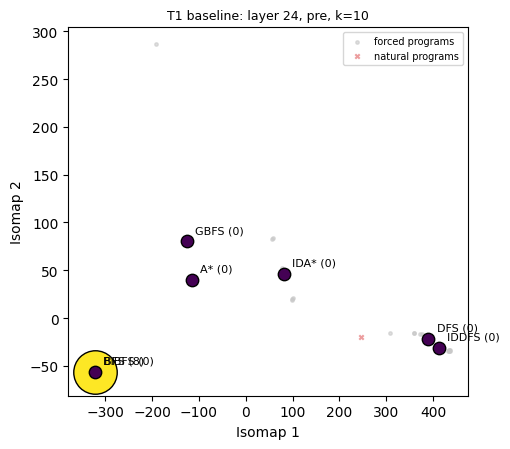

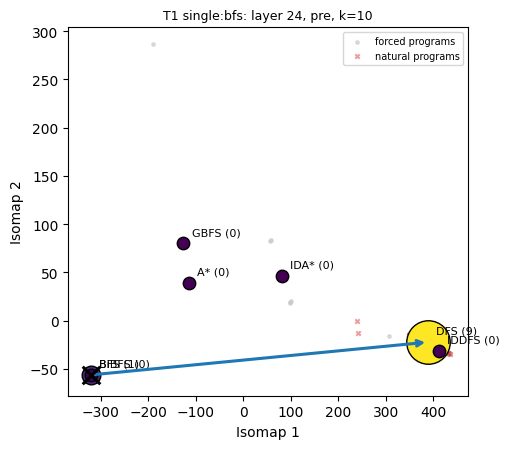

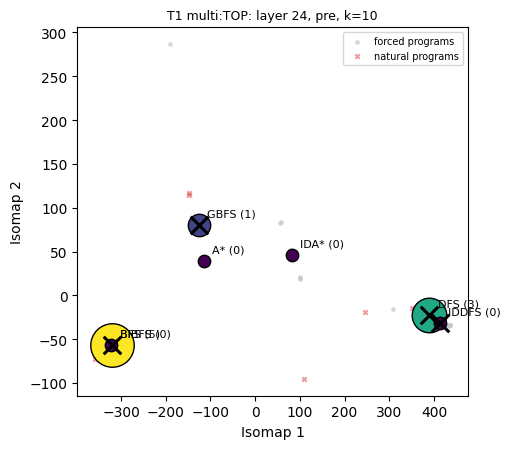

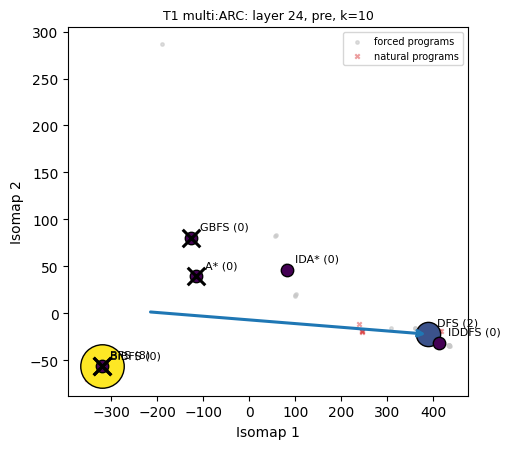

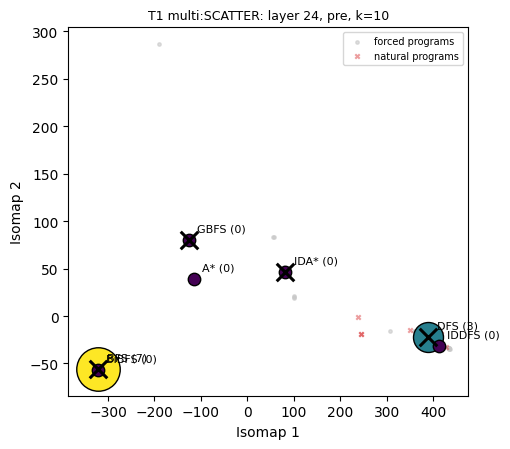

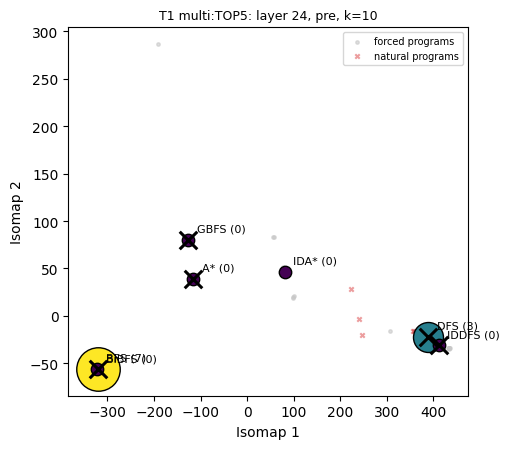

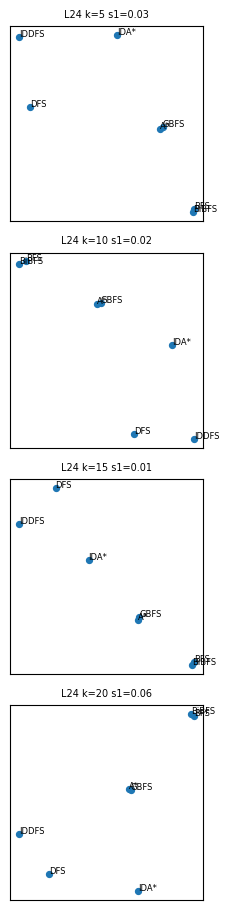

10:10:17|INFO   |manifold t1: stress1 0.019; NN stability 0.75


10:10:33|INFO   |persistence t1: no evidence of a loop


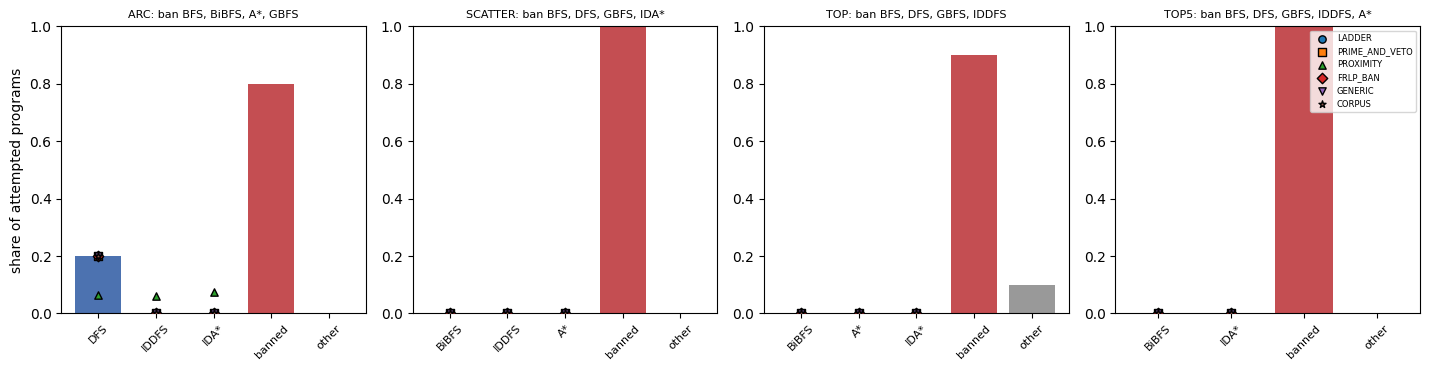

10:10:33|INFO   |figures: ['fig_landing']


10:10:33|INFO   |stage manifold done in 18.1s


centroid MDS stress-1:                 demo 0.019 | full run 0.025
nearest-neighbour stability (settings): demo 0.75 | full run 0.70
nearest neighbour under the bootstrap:  demo 0.95 | full run 0.96


,algorithm,nearest 3 (demo),nearest 3 (full run)
0,BFS,BiBFS > A* > GBFS,BiBFS > A* > GBFS
1,DFS,IDDFS > IDA* > A*,IDDFS > IDA* > GBFS
2,BiBFS,BFS > A* > GBFS,BFS > A* > GBFS
3,IDDFS,DFS > IDA* > GBFS,DFS > IDA* > GBFS
4,A*,GBFS > BFS > BiBFS,GBFS > BiBFS > BFS
5,GBFS,A* > BiBFS > BFS,A* > BFS > BiBFS
6,IDA*,GBFS > A* > DFS,GBFS > A* > IDDFS


persistent H1, demo: no evidence of a loop (centroid-bootstrap p = 1.00, per-sample p = 1.00); full run: no evidence of a loop


In [22]:
main("manifold")
man = read_json(RESULTS_DIR / "manifold.json")["tasks"]["t1"]
pers = read_json(RESULTS_DIR / "persistence.json")["t1"]
ref_man = MD["full_run_reference"]["manifold_t1"]
print(f"centroid MDS stress-1:                 demo {man['primary_stress1']:.3f} | full run {ref_man['primary_stress1']:.3f}")
print(f"nearest-neighbour stability (settings): demo {man['nearest_neighbour_stability_vs_primary']:.2f} | "
      f"full run {ref_man['nearest_neighbour_stability_vs_primary']:.2f}")
print(f"nearest neighbour under the bootstrap:  demo {man['bootstrap_nearest_same']:.2f} | "
      f"full run {ref_man['bootstrap_nearest_same']:.2f}")
display(pd.DataFrame([{"algorithm": SHORT[a], "nearest 3 (demo)": " > ".join(SHORT[b] for b in man["primary_nearest"][a]),
                       "nearest 3 (full run)": " > ".join(SHORT[b] for b in ref_man["primary_nearest"][a])}
                      for a in man["algorithms"]]))
print(f"persistent H1, demo: {pers['verdict']} (centroid-bootstrap p = {pers['centroid_bootstrap']['p']:.2f}, "
      f"per-sample p = {pers['per_sample']['p']:.2f}); full run: {MD['full_run_reference']['persistence_t1']['verdict']}")

## S12 — Per-row forecasts (`mb/outputs.py`)

Every row of `method_out.json` carries two predictions:
- `predict_default`: the task's baseline algorithm, i.e. "the ban changes nothing";
- `predict_ladder`: the highest-ranked non-banned algorithm by corrected FRLP base value (for multi-bans, the committed LADDER top-1).

Forced rows add `predict_requested`. Multi-ban rows add every committed top-1 survivor: `predict_pnv`, `predict_proximity`, `predict_frlp`, `predict_generic` and `predict_corpus`. The cell re-derives these for the demo rows with the original `row_predictions`, and compares them with the stored ones.

In [23]:
# mb/outputs.py
PRED_KEYS = {"LADDER": "predict_ladder", "PRIME_AND_VETO": "predict_pnv", "PROXIMITY": "predict_proximity",
             "FRLP_BAN": "predict_frlp", "GENERIC": "predict_generic", "CORPUS": "predict_corpus"}


DEFAULT = {"t1": "bfs", "t2": "dijkstra"}


def ladder_ranking() -> dict[str, list[str]]:
    """Analysis-catalogue algorithms ordered by the corrected FRLP base value L_j + log(as-requested share)."""
    import math

    keep = read_json(RESULTS_DIR / "catalogue_keep.json")
    cat = keep.get("analysis_catalogue_final", keep["analysis_catalogue"])
    out = {}
    for task in ("t1", "t2"):
        base = {r["algorithm"]: r["L"] for r in read_jsonl(RESULTS_DIR / "frlp_cells.jsonl")
                if r["task"] == task and r["condition"] == "base" and r["half"] == "all" and "variant" not in r}
        lc = {a: base[a] + math.log(max(keep["tasks"][task][a]["share"], 1e-9)) for a in cat[task] if a in base}
        out[task] = sorted(lc, key=lambda a: -lc[a])
    return out


def row_predictions(r: dict[str, Any], ladder: dict[str, list[str]], fcs: dict[str, Any]) -> dict[str, str]:
    """predict_default: the task's modal baseline algorithm (no-change baseline). predict_ladder: the highest-ranked
    non-banned algorithm by corrected FRLP base value (for multi-bans: the committed LADDER top-1). predict_requested:
    the requested algorithm of a forced prompt. Multi-ban rows also carry every committed top-1 survivor."""
    task = r["task"]
    banned = set(r.get("banned") or [])
    pred = {"predict_default": DEFAULT[task]}
    cand = [a for a in ladder[task] if a not in banned]
    if cand:
        pred["predict_ladder"] = cand[0]
    if r["condition"].startswith(("forced:", "forced_desc:")) and r.get("algorithm"):
        pred["predict_requested"] = str(r["algorithm"])
    if r["condition"].startswith("multi:"):
        fc = fcs.get(r["condition"].split(":", 1)[1])
        if fc:
            for f, key in PRED_KEYS.items():
                if f in fc["top1"]:
                    pred[key] = str(fc["top1"][f])
    return pred


def stage_outputs() -> None:
    # notebook: the original writes data/samples.jsonl and method_out.json (+ mini / preview) from every raw and
    # labelled file; here the per-row predictions of the demo rows are re-derived and checked against the stored ones
    fcs = {p.stem.replace("forecasts_", ""): read_json(p) for p in sorted((ROOT / "predictions").glob("forecasts_*.json"))}
    ladder = ladder_ranking()
    same = collections.Counter()
    for r, e in zip(ROWS, EXAMPLES):
        for k, v in row_predictions(r, ladder, fcs).items():
            same[f"{k}: {'same' if v == e.get(k) else 'DIFFERENT'}"] += 1
    write_json(RESULTS_DIR / "predictions_check.json", {"ladder_ranking": ladder, "check": dict(same)})
    logger.info(f"ladder ranking t1: {ladder['t1']}")


main("outputs")
for k, v in sorted(read_json(RESULTS_DIR / "predictions_check.json")["check"].items()):
    print(f"{k:<32} {v}")

10:10:33|INFO   |ladder ranking t1: ['bfs', 'dfs', 'gbfs', 'iddfs', 'astar', 'bibfs', 'idastar']


10:10:33|INFO   |stage outputs done in 0.0s


predict_corpus: same             40
predict_default: same            100
predict_frlp: same               40
predict_generic: same            40
predict_ladder: same             100
predict_pnv: same                40
predict_proximity: same          40
predict_requested: same          42


## Results summary

The cell below sets the demo subset (10 programs per condition) next to the full run (100 per condition) and adds two post hoc checks:
- **mix homogeneity**: is the BFS/DFS mix the same across the four multi-bans?
- **predictor accuracy**: how often does each per-row predictor name the program that was actually written?

The figure shows the landing composition per condition, with the banned share hatched. Beside it are the algorithm centroids in activation space: the full-run MDS, with the demo MDS aligned onto it by an orthogonal Procrustes rotation.

BFS share among BFS + DFS programs per multi-ban
  demo    : {'TOP': 0.62, 'ARC': 0.8, 'SCATTER': 0.7, 'TOP5': 0.7} chi-square p = 0.88
  full run: {'TOP': 0.69, 'ARC': 0.63, 'SCATTER': 0.72, 'TOP5': 0.64} chi-square p = 0.48

predictor hit rate on the 40 demo multi-ban programs: {'default': 0.68, 'ladder': 0.05, 'pnv': 0.05, 'proximity': 0.0, 'frlp': 0.05, 'generic': 0.05, 'corpus': 0.05}
full run: {'per_row_top1_accuracy': {'baseline|predict_default': 1.0, 'baseline|predict_ladder': 1.0, 'forced|predict_default': 0.275, 'forced|predict_ladder': 0.275, 'forced|predict_requested': 0.657, 'los|predict_default': 0.612, 'los|predict_ladder': 0.292, 'multi|predict_corpus': 0.098, 'multi|predict_default': 0.635, 'multi|predict_frlp': 0.092, 'multi|predict_generic': 0.092, 'multi|predict_ladder': 0.092, 'multi|predict_pnv': 0.098, 'multi|predict_proximity': 0.0, 'single|predict_default': 0.15, 'single|predict_ladder': 0.845}, 'note': "share of programs whose mechanism label equals the predic

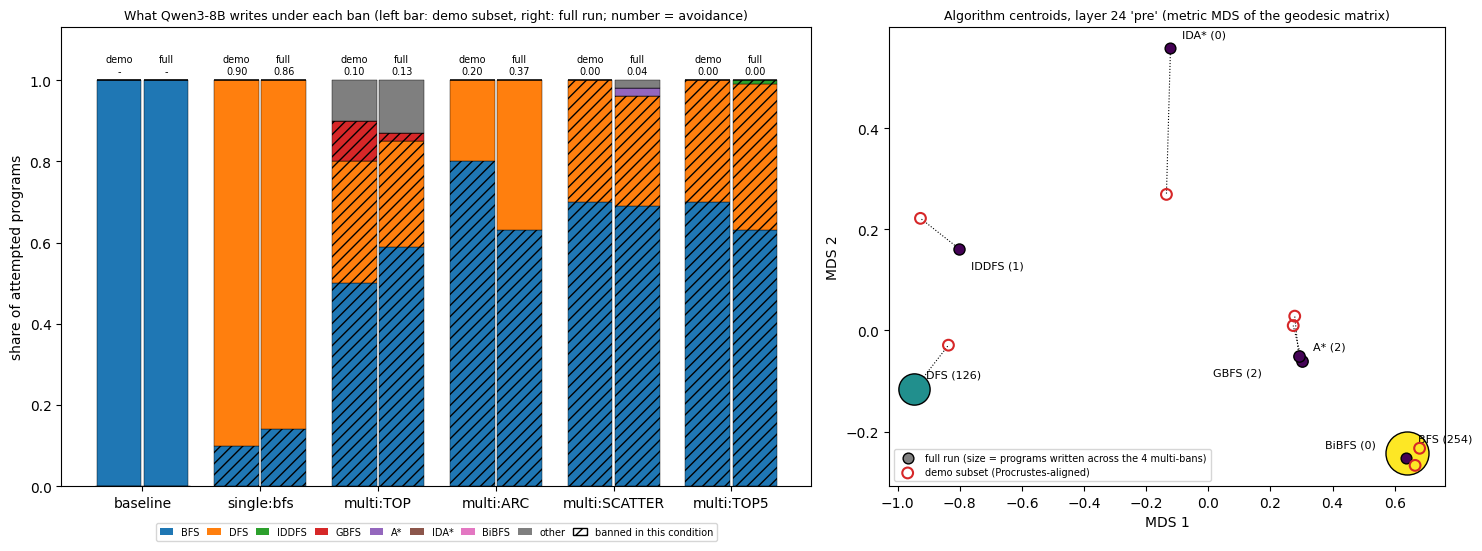

In [24]:
land = read_json(RESULTS_DIR / "landing.json")
man = read_json(RESULTS_DIR / "manifold.json")["tasks"]["t1"]
ref = MD["full_run_reference"]
MULTI = CONDS[2:]

# 1) post hoc (not pre-registered): is the BFS/DFS mix the same across the four multi-bans?
mix = np.array([[land["conditions"][k]["fine_labels"].get(a, 0) for a in ("bfs", "dfs")] for k in MULTI])
p_mix = chi2_contingency(mix)[1] if (mix.sum(axis=0) > 0).all() else float("nan")
print("BFS share among BFS + DFS programs per multi-ban")
print("  demo    :", {k.split(":")[1]: round(float(b / max(b + d, 1)), 2) for k, (b, d) in zip(MULTI, mix)},
      f"chi-square p = {p_mix:.2f}")
ph = ref["posthoc_mix_homogeneity"]
print("  full run:", {s: round(b / (b + d), 2) for s, (b, d) in ph["bfs_dfs_counts"].items()},
      f"chi-square p = {ph['chi2_p']:.2f}")

# 2) per-row predictors on the multi-ban rows: share of programs whose label equals the prediction
mrows = [e for e in EXAMPLES if e["metadata_condition"].startswith("multi:")]
pkeys = ["predict_default", "predict_ladder", "predict_pnv", "predict_proximity", "predict_frlp", "predict_generic",
         "predict_corpus"]
print(f"\npredictor hit rate on the {len(mrows)} demo multi-ban programs:",
      {k.replace("predict_", ""): round(float(np.mean([e.get(k) == e["output"] for e in mrows])), 2) for k in pkeys})
print("full run:", ref["predictor_accuracy"])

# 3) figure: landing composition (banned share hatched) and the centroid geometry
fig, (ax, bx) = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1.35, 1]})
cats = ["bfs", "dfs", "iddfs", "gbfs", "astar", "idastar", "bibfs", "other"]
cmap = plt.get_cmap("tab10")
x = np.arange(len(CONDS))
for off, src, get in ((-0.2, "demo", lambda k: land["conditions"][k]), (0.2, "full", lambda k: ref["landing_conditions"][k])):
    bottom = np.zeros(len(CONDS))
    for ci, cat in enumerate(cats):
        vals = np.array([(get(k)["counts"].get(cat, 0) + get(k)["counts"].get("banned:" + cat, 0)) / max(get(k)["attempted"], 1)
                         for k in CONDS])
        for xi, k, v, b in zip(x, CONDS, vals, bottom):
            banned = cat in land["conditions"][k]["banned"]
            ax.bar(xi + off, v, 0.38, bottom=b, color=cmap(ci), edgecolor="k", lw=0.3, hatch="///" if banned else None)
        if off < 0:
            ax.bar(0, 0, color=cmap(ci), label=SHORT[cat])
        bottom += vals
    for xi, k in zip(x, CONDS):
        av = get(k)["avoidance"] if land["conditions"][k]["banned"] else None
        ax.text(xi + off, 1.01, src + (f"\n{av:.2f}" if av is not None else "\n-"), ha="center", va="bottom", fontsize=7)
ax.bar(0, 0, color="w", edgecolor="k", hatch="///", label="banned in this condition")
ax.set_xticks(x, [k.split("|")[1] for k in CONDS])
ax.set_ylim(0, 1.13)
ax.set_ylabel("share of attempted programs")
ax.set_title("What Qwen3-8B writes under each ban (left bar: demo subset, right: full run; number = avoidance)", fontsize=9)
ax.legend(fontsize=7, ncol=9, loc="upper center", bbox_to_anchor=(0.5, -0.07), columnspacing=0.8, handlelength=1.4)

A = np.array([ref["manifold_t1"]["primary_mds"][a] for a in man["algorithms"]])
B = np.array([man["primary_mds"][a] for a in man["algorithms"]])
A, B = A - A.mean(0), B - B.mean(0)
R, sc = orthogonal_procrustes(B, A)
B = B @ R * (sc / (B ** 2).sum())  # rotation / reflection plus one uniform scale onto the full-run layout
landed = {a: sum(ref["landing_conditions"][k]["counts"].get(a, 0) + ref["landing_conditions"][k]["counts"].get("banned:" + a, 0)
                 for k in MULTI) for a in man["algorithms"]}
mx = max(landed.values())
offsets = {"bfs": (8, 8), "bibfs": (-58, 8), "astar": (8, 8), "gbfs": (-62, -14), "dfs": (8, 8), "iddfs": (8, -14),
           "idastar": (8, 8)}  # coincident centroids (BFS / BiBFS, A* / GBFS) get their labels on opposite sides
for a, pa, pb in zip(man["algorithms"], A, B):
    bx.plot([pa[0], pb[0]], [pa[1], pb[1]], "k:", lw=0.8)
    bx.scatter(*pa, s=60 + 900 * landed[a] / mx, color=plt.get_cmap("viridis")(landed[a] / mx), edgecolor="k", zorder=3)
    bx.scatter(*pb, s=60, facecolor="none", edgecolor="#d62728", lw=1.5, zorder=4)
    bx.annotate(f"{SHORT[a]} ({landed[a]})", pa, xytext=offsets.get(a, (8, 8)), textcoords="offset points", fontsize=8)
bx.scatter([], [], s=60, color="grey", edgecolor="k", label="full run (size = programs written across the 4 multi-bans)")
bx.scatter([], [], s=60, facecolor="none", edgecolor="#d62728", lw=1.5, label="demo subset (Procrustes-aligned)")
bx.legend(fontsize=7, loc="best")
bx.set_title(f"Algorithm centroids, layer {PRIMARY['layer']} '{PRIMARY['pos']}' (metric MDS of the geodesic matrix)", fontsize=9)
bx.set_xlabel("MDS 1")
bx.set_ylabel("MDS 2")
plt.tight_layout()
plt.show()

## What the demo shows

**The pipeline reproduces from the demo data.** Running the original code on the 100 programs:
- all 50 single- and multi-ban prompts are rebuilt exactly, and match the copies committed before session 2;
- the AST rules give the stored label for 100/100 programs, and `combine()` gives the stored final label for 100/100;
- the six forecasts of every banned set are recomputed exactly from the FRLP cells: top-1, probabilities and implied avoidance;
- every `predict_*` field is re-derived.

The hash chain links every line to the previous one, and every payload in the demo data matches its committed sha256. The one reported problem is the payload of line 0 (`frozen_prompts.json`, 0.95 MB), which the demo data does not include.

**Behaviour: a single ban substitutes, a list ban does not.**
- With 10 programs per condition, the baseline is all BFS.
- Banning BFS alone gives DFS 9/10: avoidance 0.90 (full run 0.86).
- Every multi-ban fails its gate. Demo avoidance is 0.10 / 0.20 / 0.00 / 0.00 for TOP / ARC / SCATTER / TOP5; the full run gave 0.13 / 0.37 / 0.04 / 0.00.
- Under the lists the model keeps writing the banned BFS or DFS. Half or more of those programs never name their mechanism (full run: 41–92%); their most common self-name is "backtrack".

**Geometry: a stable map, but not a circle.** The 42 forced programs at one layer reproduce the committed geometry:
- the same nearest pairs: BFS–BiBFS, A*–greedy, DFS–IDDFS;
- a centroid MDS stress-1 of about 0.02;
- the same EDGE and OPPOSITE survivors for all four committed sets.

TOP and TOP5 come from the FRLP ladder and are identical to the committed sets. ARC and SCATTER depend on the noisier seriation and change. Persistent homology finds no loop, so "the opposite side of a circle" is not defined for this model.

**Where the probability goes.**
- Survivor mass appears only under ARC, and all of it goes to DFS.
- Every ladder-type forecast (LADDER, PRIME_AND_VETO, FRLP_BAN, GENERIC, CORPUS) named DFS, and beats uniform by +1.06 nats per program. PROXIMITY named IDA* (the survivor nearest the banned set on the manifold) and missed (−0.02).
- On the multi-ban programs, the "nothing changes" default (BFS) is right 68% of the time (full run 64%). No survivor forecast exceeds 5%.

So the ban does not push the model along its activation-space manifold, neither to the edge of the banned region nor to the opposite side:
- A single ban moves it one rung down its own likelihood ladder: to DFS, not to BFS's nearest activation-space neighbour, BiBFS.
- A long list barely moves it. The BFS/DFS mix is the same across the four lists (demo chi-square p = 0.88; full run 0.48), like a generic perturbation of the default.

**Caveats.**
- The demo has 10 programs per condition, one layer and two token positions. Its bootstrap and null-test numbers are coarser than the full run's.
- The runtime tracer and the LLM judge are not re-run; their stored labels are used.
- The FRLP cells have an effective sample size below 5 in most cells.
- The bf16 scoring noise is about 1 nat per program.